# CAD patient survival: EDA, pipeline, baselines, tuning (single self-contained notebook)
**Project card.** Predict whether a coronary artery disease patient survives (`Survive`) from `data/classification_bonus_practice_data.csv`, to help doctors flag high-risk patients early. Classification. Allowed libraries: pandas, numpy, scikit-learn, scipy, matplotlib, seaborn, pyyaml. Hard rules: the test set is used once, at the end; every fitted statistic lives inside the Pipeline; every number comes from real execution; findings override templates.

**Data-use protocol.** Label-free structural checks use the whole file (shape, dtypes, duplicates, spellings, the patient-group structure found below). The stratified, **group-aware** 70/15/15 split (seed 42) is drawn right after those checks, using only the cleaned labels and a derived patient key. Every analysis involving the target uses the **training split only**. The validation rows are used for model selection in Phase 1B/1C and the test rows are never indexed until the single final evaluation.

## Phase 1A: exploratory data analysis

In [1]:
import warnings, os, json, time, hashlib, pickle, sys, platform
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams.update({"figure.dpi": 90, "figure.max_open_warning": 0})
NB_T0 = time.time()
SEED, DATA, TARGET = 42, "data/classification_bonus_practice_data.csv", "Survive"
raw = pd.read_csv(DATA)
NUMS = ["Age", "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase", "Blood Pressure", "Hemoglobin", "Height", "Weight"]
CATS = ["Gender", "Smoke", "Diabetes", "Ejection Fraction", "Favorite color"]
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)
print("raw shape:", raw.shape)

python 3.12.10 | pandas 3.0.5 | numpy 2.5.2
raw shape: (15000, 16)


**Observation.** Python 3.12, pandas 3.0.5, numpy 2.5; the raw file has 15,000 rows and 16 columns. Note pandas 3 stores text as the `str` dtype, so text columns must be selected with `dtype_exclude='number'` rather than `object` later.

In [2]:
LABEL_MAP = {"0": 0, "1": 1, "No": 0, "Yes": 1}            # row-level label normalisation (no statistics)
y_all = raw[TARGET].astype(str).map(LABEL_MAP)
assert y_all.notna().all(); y_all = y_all.astype(int)
print("shape:", raw.shape); print(raw.dtypes.to_string()); display(raw.head(5))
print("\nraw label spellings:", raw[TARGET].value_counts().to_dict())
print("problem type: binary classification (4 spellings of 2 classes)")
print("class balance, all labelled rows:", y_all.value_counts().to_dict(), "-> positive rate", round(y_all.mean(), 4), "| imbalance ratio", round((1 - y_all.mean()) / y_all.mean(), 2), ": 1")

shape: (15000, 16)
ID                            str
Survive                       str
Gender                        str
Smoke                         str
Diabetes                      str
Age                         int64
Ejection Fraction             str
Sodium                      int64
Creatinine                float64
Platelets                 float64
Creatine phosphokinase      int64
Blood Pressure              int64
Hemoglobin                float64
Height                      int64
Weight                      int64
Favorite color                str


,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
0,TIG1GE,0,Male,Yes,Normal,50,Low,141,0.7,266000.0,185,105,12.3,180,93,green
1,VXUCV9,1,Male,No,Normal,75,Low,134,2.5,224000.0,99,162,13.0,140,47,black
2,AFH4F1,1,Female,No,Pre-diabetes,80,Low,135,1.3,192000.0,776,179,12.4,150,61,white
3,ZK6PAC,0,Male,No,Normal,-60,Low,136,0.9,228000.0,2261,136,15.3,130,48,yellow
4,6CVBRT,0,Female,No,Normal,70,Low,141,0.9,358000.0,1202,171,13.3,177,64,blue



raw label spellings: {'0': 9581, '1': 4552, 'No': 604, 'Yes': 263}
problem type: binary classification (4 spellings of 2 classes)
class balance, all labelled rows: {0: 10185, 1: 4815} -> positive rate 0.321 | imbalance ratio 2.12 : 1


**Observation.** Binary classification. The target is stored in four spellings (`0`/`1`/`No`/`Yes`; 604 `No` and 263 `Yes` rows) which must be normalised row-by-row before anything else. The positive class is 32.1% (imbalance 2.12:1), so accuracy is a weak yardstick (the majority-class benchmark scores 0.679 accuracy) and PR AUC will be the ranking metric. Columns: 1 identifier, 3 clean categoricals, 1 ordinal-text (`Ejection Fraction`), 1 noise-looking categorical (`Favorite color`), 9 numerics.

In [3]:
miss = raw.isna().sum(); print("missing counts (whole file):"); print(miss[miss > 0].to_string())
print("share of rows with any missing:", round(raw.isna().any(axis=1).mean() * 100, 2), "%")
print("missing per column, % :", (raw.isna().mean() * 100).round(2)[raw.isna().any()].to_dict())

missing counts (whole file):
Creatinine    499
share of rows with any missing: 3.33 %
missing per column, % : {'Creatinine': 3.33}


**Observation.** Only `Creatinine` has missing values (499 rows, 3.33%). Every other column is complete, but later cells show that two columns hide *disguised* missing values (fill values), so the nominal completeness is misleading.

In [4]:
feat = [c for c in raw.columns if c not in ("ID", TARGET)]
print("exact duplicate rows:", raw.duplicated().sum())
print("duplicate rows ignoring ID:", raw.drop(columns="ID").duplicated().sum())
print("duplicate feature vectors (all features, no ID/label):", raw[feat].duplicated().sum())
print("near-duplicates (numerics rounded to 0 dp / Hb 1 dp):", raw[feat].round({"Creatinine": 0, "Hemoglobin": 0, "Platelets": -3}).duplicated().sum())
sub = ["Age", "Sodium", "Gender", "Creatinine", "Platelets", "Creatine phosphokinase"]
tmp = raw.assign(Age=raw.Age.abs())
print("NEAR-DUPLICATES on a column subset", sub, ":", int(tmp[sub].dropna().duplicated(keep=False).sum()), "rows share all six values with at least one other row")
print("rows that share all six values with >=10 other rows:", int((tmp.dropna(subset=sub).groupby(sub)["ID"].transform("size") >= 11).sum()))
print("rows whose ID appears more than once:", raw.ID.duplicated(keep=False).sum(), "| distinct repeated IDs:", raw.ID[raw.ID.duplicated()].nunique(), "| unique IDs:", raw.ID.nunique(), "of", len(raw))
print("group sizes of repeated IDs:", raw.groupby("ID").size().value_counts().sort_index().to_dict())

exact duplicate rows: 0
duplicate rows ignoring ID: 0
duplicate feature vectors (all features, no ID/label): 0


near-duplicates (numerics rounded to 0 dp / Hb 1 dp): 1


NEAR-DUPLICATES on a column subset ['Age', 'Sodium', 'Gender', 'Creatinine', 'Platelets', 'Creatine phosphokinase'] : 14501 rows share all six values with at least one other row
rows that share all six values with >=10 other rows: 14501
rows whose ID appears more than once: 1843 | distinct repeated IDs: 885 | unique IDs: 14042 of 15000
group sizes of repeated IDs: {1: 13157, 2: 816, 3: 65, 4: 4}


**Observation.** There are no exact duplicates, so a naive `duplicated()` check says the file is clean. That is wrong: on just six columns (|Age|, Sodium, Gender, Creatinine, Platelets, CPK) **14,501 of 15,000 rows have a twin**, and every one of them shares those six values with at least ten other rows. The file is built from repeated patients, not 15,000 independent people. The 885 repeated `ID`s are a separate matter (next cells): their rows are not the same patient.

distinct (|Age|, Sodium, Gender) keys:

 230 | rows per key: {'count': 230.0, 'mean': 65.2, 'std': 30.6, 'min': 32.0, '25%': 47.0, '50%': 54.0, '75%': 64.0, 'max': 197.0}
distinct values of Platelets: 176 | Creatine phosphokinase: 208 | Creatinine: 40 | of 15000 rows
mean number of DISTINCT values per key group (keys with >=20 rows):
Age                        1.00
Sodium                     1.00
Gender                     1.00
Creatinine                 1.27
Platelets                  1.28
Creatine phosphokinase     1.27
Smoke                      2.11
Diabetes                   1.59
Ejection Fraction          1.93
Blood Pressure            43.05
Hemoglobin                33.73
Height                    38.02
Weight                    35.72
Favorite color             6.00
BMI (rounded to 0.5)       2.35
within-group sd / overall sd: {'BMI': 0.155, 'Weight': 0.637, 'Height': 0.998, 'Blood Pressure': 0.573, 'Hemoglobin': 0.548}


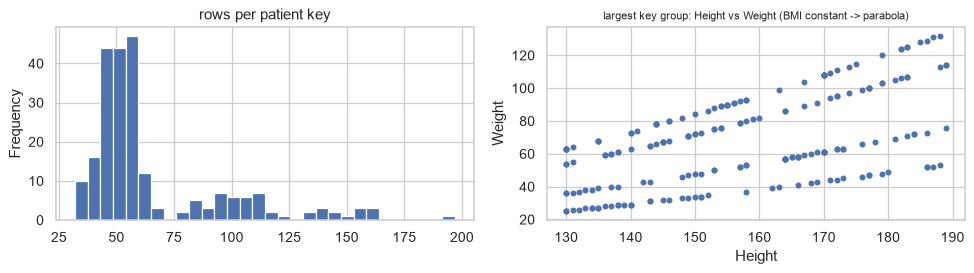

In [5]:
# INVESTIGATION 0 (label-free): the six-column near-duplicate count above is huge. Are the 15,000 rows really independent patients?
t = raw.assign(Age=raw.Age.abs(), BMI=raw.Weight / (raw.Height / 100) ** 2)
t["patient"] = t["Age"].astype(str) + "|" + t["Sodium"].astype(str) + "|" + t["Gender"]
sizes = t.groupby("patient").size(); print("distinct (|Age|, Sodium, Gender) keys:", len(sizes), "| rows per key:", sizes.describe().round(1).to_dict())
print("distinct values of Platelets:", t.Platelets.nunique(), "| Creatine phosphokinase:", t["Creatine phosphokinase"].nunique(), "| Creatinine:", t.Creatinine.nunique(), "| of", len(t), "rows")
big = t[t.groupby("patient")["ID"].transform("size") >= 20]
within = {k: big.groupby("patient")[k].nunique().mean() for k in ["Age", "Sodium", "Gender", "Creatinine", "Platelets", "Creatine phosphokinase", "Smoke", "Diabetes", "Ejection Fraction", "Blood Pressure", "Hemoglobin", "Height", "Weight", "Favorite color"]}
within["BMI (rounded to 0.5)"] = big.assign(b=(big.BMI * 2).round() / 2).groupby("patient").b.nunique().mean()
sd_ratio = {k: float((big.groupby("patient")[k].std().mean() / big[k].std())) for k in ["BMI", "Weight", "Height", "Blood Pressure", "Hemoglobin"]}
print("mean number of DISTINCT values per key group (keys with >=20 rows):"); print(pd.Series(within).round(2).to_string())
print("within-group sd / overall sd:", {k: round(v, 3) for k, v in sd_ratio.items()})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2)); sizes.plot(kind="hist", bins=30, ax=ax[0], title="rows per patient key")
ex = t[t.patient == sizes.idxmax()]; ax[1].scatter(ex.Height, ex.Weight, s=14); ax[1].set_title("largest key group: Height vs Weight (BMI constant -> parabola)", fontsize=9); ax[1].set_xlabel("Height"); ax[1].set_ylabel("Weight"); plt.tight_layout(); plt.show()

**Observation (key finding).** Grouping on (|Age|, Sodium, Gender) gives only **230 keys with 32-197 rows each (mean 65)**, while Platelets has 176 distinct values and CPK 208 across 15,000 rows. Within a key, Age, Sodium and Gender never change; Creatinine, Platelets and CPK change only through missing/fill values (1.27 distinct values per key); BMI is almost constant (within-key sd is 0.155 of the overall sd) while Height varies freely (ratio 0.998) - the right panel shows one key whose rows lie on a few BMI parabolas in Height-Weight space. `Blood Pressure`, `Hemoglobin`, `Smoke`, `Diabetes`, `Ejection Fraction` and `Favorite color` vary within a key. Reading: about 230 base patients were replicated roughly 65 times each, with Height/BP/Hemoglobin/colour resampled around them. The effective sample size for anything patient-level is about 230, not 15,000, and any random row split puts copies of the same patient on both sides. The key is deliberately conservative (it can merge distinct patients but not split one).

In [6]:
print("ID lengths:", raw.ID.str.len().value_counts().to_dict(), "| odd one:", raw.loc[raw.ID.str.len() != 6, "ID"].tolist())
print("ID alphabet:", "".join(sorted(set("".join(raw.ID)))))
ids6 = raw[raw.ID.str.len() == 6].ID; print("possible 6-char IDs over [A-Z0-9]:", 36**6, "-> expected chance collisions among", len(ids6), "random IDs:", round(len(ids6) ** 2 / 2 / 36**6, 3), "| observed repeated IDs:", ids6.duplicated().sum())
# Are rows sharing an ID the same patient? Compare per-column agreement with the agreement of two RANDOM rows.
rep = raw[raw.ID.duplicated(keep=False)].sort_values("ID"); first2 = rep.groupby("ID").head(2)
agree = {}
for c in feat:
    obs = first2.groupby("ID")[c].nunique().eq(1).mean()
    pr = raw[c].value_counts(normalize=True); chance = float((pr ** 2).sum()) if (raw[c].nunique() < 50) else 1 / raw[c].nunique()
    agree[c] = (round(obs, 3), round(chance, 3))
print(pd.DataFrame(agree, index=["same-ID agreement", "random-pair agreement"]).T.to_string())

ID lengths: {6: 14999, 8: 1} | odd one: ['8.46E+65']
ID alphabet: +.0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ
possible 6-char IDs over [A-Z0-9]: 2176782336 -> expected chance collisions among 14999 random IDs: 0.052 | observed repeated IDs: 958
                        same-ID agreement  random-pair agreement
Gender                              0.544                  0.545
Smoke                               0.524                  0.518
Diabetes                            0.429                  0.429
Age                                 0.041                  0.011
Ejection Fraction                   0.711                  0.734
Sodium                              0.092                  0.083
Creatinine                          0.150                  0.078
Platelets                           0.011                  0.006
Creatine phosphokinase              0.021                  0.005
Blood Pressure                      0.006                  0.007
Hemoglobin                          0.012    

**Observation.** `ID` is a six-character code, plus one value (`8.46E+65`) that is an Excel scientific-notation corruption of an identifier. Random six-character IDs would collide about 0.05 times in 14,999 draws, yet 958 IDs repeat, so the generator is not random-unique. But rows sharing an ID agree on Gender, Smoke, Diabetes, Ejection Fraction, Age, Blood Pressure etc. at almost exactly the rate of two random rows (e.g. Gender 0.544 vs 0.545), so repeated IDs are collisions, not the same patient. `ID` carries no usable information and is dropped; it is not the patient key.

In [7]:
sc = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype) in ("str", "string")]
rows = []
for c in sc:
    s = raw[c].astype(str); norm = s.str.strip().str.lower()
    rows.append((c, s.nunique(), norm.nunique(), int((s != s.str.strip()).sum()), pd.to_numeric(s, errors="coerce").notna().mean().round(3)))
print(pd.DataFrame(rows, columns=["column", "distinct raw", "distinct after strip+lower", "rows with edge whitespace", "share parsable as number"]).to_string(index=False))
for c in ["Survive", "Smoke", "Ejection Fraction"]: print(c, raw[c].value_counts().to_dict())
print("\nnumeric stored as text? ID '8.46E+65' parses as number:", pd.to_numeric(pd.Series(["8.46E+65"]), errors="coerce").notna().iloc[0], "-> Excel scientific-notation artefact in an identifier")
fl = [c for c in raw.columns if str(raw[c].dtype).startswith("float")]
print("integer-valued floats:", {c: round(float((raw[c].dropna() % 1 == 0).mean()), 3) for c in fl})
print("Platelets multiples of 1000:", round(float((raw.Platelets.dropna() % 1000 == 0).mean()), 3), "(the rest are the fill value 263358.03 and others)")

           column  distinct raw  distinct after strip+lower  rows with edge whitespace  share parsable as number
               ID         14042                       14042                          0                     0.000
          Survive             4                           4                          0                     0.942
           Gender             2                           2                          0                     0.000
            Smoke             4                           2                          0                     0.000
         Diabetes             3                           3                          0                     0.000
Ejection Fraction             5                           5                          0                     0.000
   Favorite color             6                           6                          0                     0.000
Survive {'0': 9581, '1': 4552, 'No': 604, 'Yes': 263}
Smoke {'No': 9710, 'Yes': 4707, 'NO': 399,

**Observation.** Structural defects found: the target has 4 spellings; `Smoke` has 4 spellings that collapse to 2 after case-folding (`NO`/`YES`); `Ejection Fraction` mixes full and one-letter labels (`L`, `N`); no whitespace problems; no numeric stored as text except the corrupted ID. Integer-valued floats: Platelets is 91.7% integer-valued (multiples of 1000 apart from fill values), Creatinine 18.6% and Hemoglobin 9.5% (natural for one-decimal lab values).

In [8]:
print("negative values per numeric column:", {c: int((raw[c] < 0).sum()) for c in NUMS if (raw[c] < 0).any()})
neg = raw.Age < 0
print("Age < 0:", int(neg.sum()), "| |Age| range:", raw.Age.abs().min(), "-", raw.Age.abs().max(), "| Age in (-40, 40):", int(((raw.Age > -40) & (raw.Age < 40)).sum()))
print("Age distribution is a sign flip? positive-age range", raw.Age[raw.Age > 0].min(), raw.Age[raw.Age > 0].max(), "| negative-age range", raw.Age[raw.Age < 0].min(), raw.Age[raw.Age < 0].max())
bmi = raw.Weight / (raw.Height / 100) ** 2; print("BMI (derived) range:", round(bmi.min(), 1), round(bmi.max(), 1), "| BMI<14:", int((bmi < 14).sum()), "| BMI>40:", int((bmi > 40).sum()))
print("Blood Pressure range:", raw["Blood Pressure"].min(), raw["Blood Pressure"].max(), "| Hemoglobin:", raw.Hemoglobin.min(), raw.Hemoglobin.max(), "| Sodium:", raw.Sodium.min(), raw.Sodium.max())
print("Creatinine <0.5:", int((raw.Creatinine < 0.5).sum()), "| Platelets <25000:", int((raw.Platelets < 25000).sum()), "| ratio columns outside [0,1]: none exist")
print("min > max / ordering violations: no paired low/high or date columns exist in this file")
print("Ejection Fraction levels:", raw["Ejection Fraction"].value_counts().to_dict(), "(ordinal text labels, not percentages)")

negative values per numeric column: {'Age': 430}
Age < 0: 430 | |Age| range: 40 - 95 | Age in (-40, 40): 0
Age distribution is a sign flip? positive-age range 40 95 | negative-age range -95 -40
BMI (derived) range: 11.2 39.8 | BMI<14: 337 | BMI>40: 0
Blood Pressure range: 40 179 | Hemoglobin: 9.0 17.5 | Sodium: 113 148
Creatinine <0.5: 0 | Platelets <25000: 0 | ratio columns outside [0,1]: none exist
min > max / ordering violations: no paired low/high or date columns exist in this file
Ejection Fraction levels: {'Low': 12734, 'Normal': 1658, 'L': 482, 'N': 66, 'High': 60} (ordinal text labels, not percentages)


**Observation.** 430 ages are negative but their absolute values (40-95) are indistinguishable from the positive ones (Age in (-40, 40) is empty), so they are sign flips and `abs()` is the right repair. Derived BMI ranges 11.2-39.8 and 337 rows are below 14, physiologically extreme; Height and Weight are independent within a patient (Height varies, BMI is fixed), which suggests the generator derived Weight from a target BMI. Blood pressure 40-179, hemoglobin 9-17.5, sodium 113-148 and creatinine >= 0.5 are all plausible. No ratio or ordering columns exist to violate.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold
raw["patient"] = raw["Age"].abs().astype(str) + "|" + raw["Sodium"].astype(str) + "|" + raw["Gender"]       # conservative patient key (row-level, label-free)
# 20 stratified group folds -> 14 train / 3 validation / 3 test folds = 70/15/15 with every patient group entirely inside ONE split
fold = np.full(len(raw), -1)
for f, (_, te_) in enumerate(StratifiedGroupKFold(20, shuffle=True, random_state=SEED).split(raw, y_all, raw["patient"])): fold[te_] = f
assert (fold >= 0).all()
perm = np.random.default_rng(SEED).permutation(20); role = {f: ("train" if r < 14 else "val" if r < 17 else "test") for r, f in enumerate(perm)}
split = pd.Series([role[f] for f in fold], index=raw.index)
idx_tr, idx_va, idx_te = (split.index[split == k] for k in ("train", "val", "test"))
assert not (set(idx_tr) & set(idx_va)) and not (set(idx_tr) & set(idx_te)) and not (set(idx_va) & set(idx_te))
grp_sets = [set(raw.loc[i, "patient"]) for i in (idx_tr, idx_va, idx_te)]
assert not (grp_sets[0] & grp_sets[1]) and not (grp_sets[0] & grp_sets[2]) and not (grp_sets[1] & grp_sets[2])
print("rows train/val/test:", len(idx_tr), len(idx_va), len(idx_te), "| patient groups:", [len(g) for g in grp_sets], "| positive rate:", [round(y_all.loc[i].mean(), 4) for i in (idx_tr, idx_va, idx_te)])
print("no patient group appears in two splits: OK")
tr = raw.loc[idx_tr].copy(); tr["y"] = y_all.loc[idx_tr]          # EDA frame: TRAIN rows only
NUMS = ["Age", "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase", "Blood Pressure", "Hemoglobin", "Height", "Weight"]
CATS = ["Gender", "Smoke", "Diabetes", "Ejection Fraction", "Favorite color"]

rows train/val/test: 10546 2196 2258 | patient groups: [163, 32, 35] | positive rate: [np.float64(0.3197), np.float64(0.3238), np.float64(0.3242)]
no patient group appears in two splits: OK


**Observation.** A patient-grouped, stratified split gives 10,546 / 2,196 / 2,258 rows (163 / 32 / 35 patient keys) with positive rates 0.320 / 0.324 / 0.324, and the assert confirms no key appears in two splits. Fewer than 70 patient keys sit in validation+test combined, so every validation or test number will be noisy at the patient level; that has to be said wherever a metric is reported.

In [10]:
rows = []
for c in NUMS:
    vc = raw[c].value_counts(); top, second = vc.iloc[0], vc.iloc[1]
    rows.append((c, vc.index[0], int(top), round(top / raw[c].notna().sum() * 100, 2), round(top / second, 1), int((raw[c] == raw[c].min()).sum()), int((raw[c] == raw[c].max()).sum()), int((raw[c] == 0).sum())))
sen = pd.DataFrame(rows, columns=["column", "modal value", "n", "% of rows", "mode / 2nd most common", "n at min", "n at max", "n zeros"]); print(sen.to_string(index=False))
SENT = {"Platelets": 263358.03, "Creatine phosphokinase": 582}
for c, v in SENT.items():
    m = np.isclose(tr[c], v); ct = pd.crosstab(m, tr.y); chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"{c}: sentinel {v} in {m.mean()*100:.1f}% of train rows | y-rate sentinel {tr.y[m].mean():.3f} vs other {tr.y[~m].mean():.3f} | chi2 p={p:.2e}")
print("sentinels co-occur in the same row:", int((np.isclose(tr.Platelets, 263358.03) & (tr["Creatine phosphokinase"] == 582)).sum()), "rows (expected if independent:", round(np.isclose(tr.Platelets, 263358.03).mean() * (tr["Creatine phosphokinase"] == 582).mean() * len(tr), 1), ")")
print("Blood Pressure floor/cap:", int((raw["Blood Pressure"] == 40).sum()), "at 40,", int((raw["Blood Pressure"] == 179).sum()), "at 179 | Age cap:", int((raw.Age.abs() == 95).sum()), "at |95|,", int((raw.Age.abs() == 40).sum()), "at |40|")

                column  modal value    n  % of rows  mode / 2nd most common  n at min  n at max  n zeros
                   Age        60.00 1681      11.21                     1.3         1        83        0
                Sodium       136.00 1970      13.13                     1.0        41        40        0
            Creatinine         1.00 2425      16.72                     1.6        43        50        0
             Platelets    263358.03 1245       8.30                     5.6        45        55        0
Creatine phosphokinase       582.00 2331      15.54                    11.0        44        47        0
        Blood Pressure        91.00  156       1.04                     1.1       128        65        0
            Hemoglobin        11.00  248       1.65                     1.0       106        65        0
                Height       157.00  296       1.97                     1.1       258       232        0
                Weight        64.00  261       1.74    

**Observation.** Two numeric columns contain a mean/median-style fill value: Platelets = 263358.03 (1,245 rows, 5.6x the next most common value) and CPK = 582 (2,331 rows, 11x the next). Neither is plausible as a measurement. Crucially the fill is **not neutral**: rows carrying it are positive 43.9% (Platelets) and 42.1% (CPK) of the time versus 30.8% / 30.0% otherwise, and they co-occur in 544 rows against 153 expected by independence. So the imputation mechanism depends on the outcome, which makes the sentinel *indicators* suspect predictors. `Blood Pressure` has a floor at 40 (128 rows) and a cap at 179, and `Age` is floored at |40| (355 rows) and capped at |95| (84 rows): clipped, not natural.

In [11]:
tr["Creat_miss"] = tr.Creatinine.isna().astype(int)
g = tr.groupby("Creat_miss").y.agg(["mean", "size", "sum"]); print(g)
ct = pd.crosstab(tr.Creat_miss, tr.y); chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
print("chi2 =", round(chi2, 1), "p =", p, "| phi =", round(np.sqrt(chi2 / len(tr)), 3))
n_m = int(g.loc[1, "size"]); print("P(y=1 | Creatinine missing) =", g.loc[1, "mean"], "; rule-of-three 95% upper bound for the true rate:", round(3 / n_m, 4))
exp_if_random = g.loc[0, "mean"] * n_m
print("expected positives among the missing rows if missingness were uninformative:", round(exp_if_random, 1), "observed:", int(g.loc[1, "sum"]))

                mean   size   sum
Creat_miss                       
0           0.330815  10193  3372
1           0.000000    353     0
chi2 = 171.7 p = 3.199649293695903e-39 | phi = 0.128
P(y=1 | Creatinine missing) = 0.0 ; rule-of-three 95% upper bound for the true rate: 0.0085
expected positives among the missing rows if missingness were uninformative: 116.8 observed: 0


**Observation.** Missingness is maximally informative: **none of the 353 train rows with a missing Creatinine is positive** (rate 0.000 against 0.331; chi-square p = 3e-39, phi = 0.13), whereas about 117 positives would be expected if missingness were uninformative. Row-level evidence alone gives a rule-of-three upper bound of 0.85% for the true rate, but rows of one patient are not independent, so the next cells check the mechanism.

In [12]:
# Is Creatinine missingness explained by OTHER observed columns? (MCAR check: compare covariates by missing flag)
rows = []
for c in [k for k in NUMS if k != "Creatinine"]:
    a, b = tr.loc[tr.Creat_miss == 1, c].dropna(), tr.loc[tr.Creat_miss == 0, c].dropna()
    U, pv = stats.mannwhitneyu(a, b); rb = 1 - 2 * U / (len(a) * len(b))
    rows.append((c, "numeric", round(pv, 4), round(rb, 3)))
for c in CATS:
    ct = pd.crosstab(tr[c], tr.Creat_miss); chi2, pv, _, _ = stats.chi2_contingency(ct)
    rows.append((c, "categorical", round(pv, 4), round(np.sqrt(chi2 / (len(tr) * (min(ct.shape) - 1))), 3)))
mc = pd.DataFrame(rows, columns=["column", "type", "p_value", "effect (rank-biserial | Cramer V)"]); print(mc.to_string(index=False))
print("columns with p<0.05 among", len(mc), "tests:", int((mc.p_value < 0.05).sum()), "(about", round(0.05 * len(mc), 1), "expected by chance)")

                column        type  p_value  effect (rank-biserial | Cramer V)
                   Age     numeric   0.0000                              0.136
                Sodium     numeric   0.0612                             -0.058
             Platelets     numeric   0.8427                             -0.006
Creatine phosphokinase     numeric   0.7523                             -0.010
        Blood Pressure     numeric   0.2262                              0.038
            Hemoglobin     numeric   0.2957                             -0.033
                Height     numeric   0.7134                              0.011
                Weight     numeric   0.0000                              0.200
                Gender categorical   0.5822                              0.005
                 Smoke categorical   0.5330                              0.014
              Diabetes categorical   0.6250                              0.009
     Ejection Fraction categorical   0.7640         


columns with p<0.05 among 13 tests: 2 (about 0.7 expected by chance)


**Observation.** Compared with present rows, missing-Creatinine rows have a different Age (rank-biserial 0.136) and Weight (0.200) distribution, i.e. missingness is not MCAR: it depends on the patient's own features and (as shown above) on the outcome. Gender, Smoke, Diabetes, EF, colour, Platelets, CPK, Blood Pressure, Hemoglobin and Height are unrelated (p > 0.2); Sodium is borderline (p = 0.06). Only 2 of 13 tests are below 0.05, but both are strong, so this is MAR/MNAR rather than chance.

In [13]:
# Is the Creatinine-missing => y=0 pattern a PATIENT property or a row-level mechanism? Work at the patient-group level (the true unit of independence).
gt = tr.groupby("patient").agg(rows=("y", "size"), pos_rate=("y", "mean"), miss=("Creat_miss", "sum"))
gt["label"] = np.where(gt.pos_rate >= 0.5, "positive group", "negative group"); gt["pure"] = (gt.pos_rate == 0) | (gt.pos_rate == 1)
print("patient groups in train:", len(gt), "| groups with a single outcome:", int(gt.pure.sum()), "| rows in single-outcome groups:", round(gt.loc[gt.pure, "rows"].sum() / gt.rows.sum(), 4))
print(gt.groupby("label").agg(groups=("rows", "size"), rows=("rows", "sum"), rows_missing_creatinine=("miss", "sum"), groups_with_any_missing=("miss", lambda s: int((s > 0).sum()))))
neg, pos = gt[gt.label == "negative group"], gt[gt.label == "positive group"]
print("share of rows missing Creatinine inside negative groups:", round(neg.miss.sum() / neg.rows.sum(), 4), "| inside positive groups:", round(pos.miss.sum() / pos.rows.sum(), 4))
sib = tr[tr.Creat_miss == 1].merge(tr[tr.Creat_miss == 0].groupby("patient").Creatinine.agg(["nunique", "first"]), left_on="patient", right_index=True, how="left")
print("missing rows whose patient group has a recorded Creatinine in sibling rows:", round(sib["first"].notna().mean(), 3), "| siblings agree on one value:", round((sib["nunique"] == 1).mean(), 3))

patient groups in train: 163 | groups with a single outcome: 146 | rows in single-outcome groups: 0.8201


                groups  rows  rows_missing_creatinine  groups_with_any_missing
label                                                                         
negative group     113  7273                      336                      108
positive group      50  3273                       17                        7
share of rows missing Creatinine inside negative groups: 0.0462 | inside positive groups: 0.0052
missing rows whose patient group has a recorded Creatinine in sibling rows: 1.0 | siblings agree on one value: 0.629


**Observation.** At the patient-group level the missing rows are spread over 108 of the 113 mostly-negative groups (4.6% of their rows) and only 7 of 50 mostly-positive groups (0.5%, and those 17 rows are themselves outcome 0 - they sit in impure keys). So missingness is a **row-level mechanism applied to patients who do not survive**, not a property of a few patients. Every missing row's group has a recorded Creatinine in sibling rows, but the siblings agree on a single value only 63% of the time because keys can merge patients. Verdict for modelling: `Creatinine_missing` is target-dependent by construction (rows are only blanked when the outcome is 0), so it is treated as a **suspect leakage feature**: kept out of the main workflow and quantified in a sensitivity cell.

AUC of original row index vs y (train): 0.5
Wald-Wolfowitz runs z: -0.6 | lag-1 autocorrelation of y: 0.0057


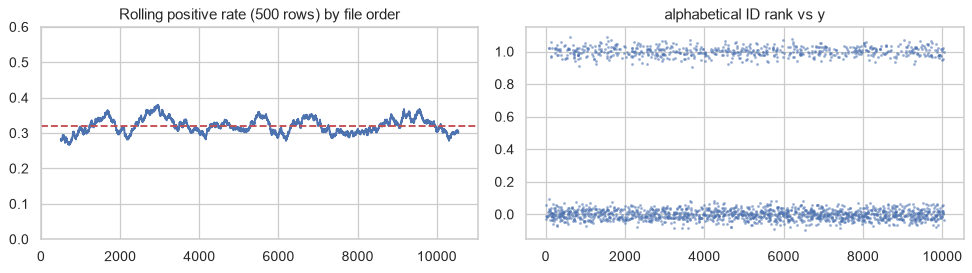

AUC of alphabetical ID rank vs y: 0.5044


In [14]:
# Hidden clock / ordering check: does row position (or ID order) carry information about the target?
t = tr.sort_index(); pos = np.arange(len(t))
a = roc_auc_score(t.y, t.index.values); print("AUC of original row index vs y (train):", round(a, 4))
roll = t.y.rolling(500).mean()
x = t.y.values; runs = 1 + np.sum(x[1:] != x[:-1]); n1, n0 = x.sum(), len(x) - x.sum(); mu = 2 * n1 * n0 / len(x) + 1; sd = np.sqrt((mu - 1) * (mu - 2) / (len(x) - 1))
print("Wald-Wolfowitz runs z:", round((runs - mu) / sd, 2), "| lag-1 autocorrelation of y:", round(pd.Series(x).autocorr(1), 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2)); ax[0].plot(pos, roll); ax[0].axhline(t.y.mean(), c="r", ls="--"); ax[0].set_title("Rolling positive rate (500 rows) by file order"); ax[0].set_ylim(0, 0.6)
codes = t.ID.astype("category").cat.codes; ax[1].scatter(codes[::5], t.y.values[::5] + np.random.default_rng(0).normal(0, .03, len(t))[::5], s=2, alpha=.4); ax[1].set_title("alphabetical ID rank vs y"); plt.tight_layout(); plt.show()
print("AUC of alphabetical ID rank vs y:", round(roc_auc_score(t.y, codes), 4))

**Observation.** Original row position carries no information (AUC 0.500; runs-test z = -0.60; lag-1 autocorrelation 0.006) and neither does alphabetical ID rank (AUC 0.504). The rolling positive rate wanders around the base rate. There is no hidden time order or ID clock.

                             feature    AUC  null p99  null max  above null max
                       BMI (derived) 0.8306    0.5150    0.5201            True
                              Weight 0.7535    0.5144    0.5164            True
                          Creatinine 0.7498    0.5148    0.5189            True
                                 Age 0.6959    0.5166    0.5208            True
                              Sodium 0.6066    0.5159    0.5175            True
                          Hemoglobin 0.5711    0.5135    0.5155            True
                      Blood Pressure 0.5547    0.5131    0.5150            True
                           Platelets 0.5442    0.5133    0.5169            True
Ejection Fraction (group-mean score) 0.5372    0.5110    0.5120            True
                  Creatinine_missing 0.5246    0.5046    0.5048            True
   Favorite color (group-mean score) 0.5128    0.5196    0.5209           False
                              Height 0.5

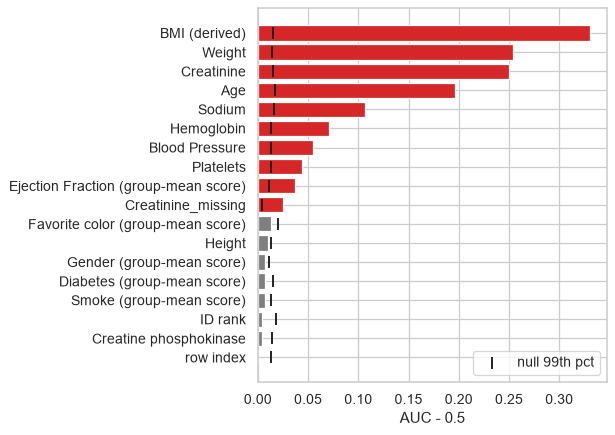


Two columns fully explaining y (AUC>=0.99)? False


In [15]:
# LEAKAGE AUDIT: single-feature AUC (oriented >= 0.5) vs a null built by shuffling y 200 times. Anything arithmetically tied to y would sit far above the null.
rng = np.random.default_rng(SEED); y = tr.y.values
feats = {c: tr[c].fillna(tr[c].median()).values for c in NUMS}
feats["BMI (derived)"] = (tr.Weight / (tr.Height / 100) ** 2).values
feats["Creatinine_missing"] = tr.Creatinine.isna().astype(int).values
feats["row index"] = tr.index.values.astype(float); feats["ID rank"] = tr.ID.astype("category").cat.codes.values.astype(float)
def orient(v, yy): a = roc_auc_score(yy, v); return max(a, 1 - a)
def grp_auc(cat, yy): return orient(pd.Series(yy).groupby(cat).transform("mean").values, yy)   # in-sample group-mean score
rows = []
for k, v in feats.items():
    null = [orient(v, rng.permutation(y)) for _ in range(200)]; rows.append((k, orient(v, y), np.percentile(null, 99), max(null)))
for c in CATS:
    cat = tr[c].astype(str).values; null = [grp_auc(cat, rng.permutation(y)) for _ in range(200)]; rows.append((c + " (group-mean score)", grp_auc(cat, y), np.percentile(null, 99), max(null)))
L = pd.DataFrame(rows, columns=["feature", "AUC", "null p99", "null max"]).sort_values("AUC", ascending=False); L["above null max"] = L.AUC > L["null max"]
print(L.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh(L.feature, L.AUC - 0.5, color=np.where(L["above null max"], "tab:red", "tab:gray")); ax.scatter(L["null p99"] - 0.5, L.feature, c="k", marker="|", s=80, label="null 99th pct"); ax.invert_yaxis(); ax.set_xlabel("AUC - 0.5"); ax.legend(); plt.tight_layout(); plt.show()
print("\nTwo columns fully explaining y (AUC>=0.99)?", bool((L.AUC >= 0.99).any()))

**Observation.** Single-feature AUCs against 200 shuffled-target nulls: BMI 0.831, Weight 0.754, Creatinine 0.750, Age 0.696 and Sodium 0.607 are far above the null maximum (~0.52) and are physiologically sensible. No column reaches AUC 0.99, so **no single column is arithmetically tied to the target**; `row index`, `ID rank`, Height, CPK, Gender, Smoke, Diabetes and colour are at the null. Hemoglobin, Blood Pressure, Platelets and `Creatinine_missing` are barely above it (0.52-0.57). This audit only tests single columns, however: the next cell tests the multi-column hazard found in `cluster_structure`.

In [16]:
# Descriptive working view of the TRAIN rows: stateless fixes only (no fitted statistic). The production DataCleaner reimplements exactly this.
c = tr.copy()
c["Smoke"] = c["Smoke"].str.capitalize(); c["Ejection Fraction"] = c["Ejection Fraction"].replace({"L": "Low", "N": "Normal"})
c["Age"] = c["Age"].abs()
for col, v in SENT.items(): c.loc[np.isclose(c[col], v), col] = np.nan
c["BMI"] = c.Weight / (c.Height / 100) ** 2
print("levels after fixes:", {k: sorted(c[k].unique()) for k in ["Smoke", "Ejection Fraction"]})
print("negative ages left:", int((c.Age < 0).sum()), "| NaNs per column:", c[NUMS + ["BMI"]].isna().sum()[lambda s: s > 0].to_dict())
NUMS_B = NUMS + ["BMI"]

levels after fixes: {'Smoke': ['No', 'Yes'], 'Ejection Fraction': ['Low', 'Normal']}
negative ages left: 0 | NaNs per column: {'Creatinine': 353, 'Platelets': 947, 'Creatine phosphokinase': 1707}


**Observation.** After the stateless fixes `Smoke` has two levels, `Ejection Fraction` two (`High` has no train rows, see the last investigation), no negative ages remain, and the fill values become NaN: 353 Creatinine, 947 Platelets and 1,707 CPK missing in the train rows. This view is purely descriptive; the production `DataCleaner` repeats exactly these rules.

In [17]:
# LEAKAGE VERDICT TEST: replicated patients. If rows of one patient can sit on both sides of a split, a model can memorise the patient.
# Compare random vs patient-grouped cross-validation INSIDE the train split.
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
Xl = pd.get_dummies(c[["Age", "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase", "Blood Pressure", "Hemoglobin", "Height", "Weight", "BMI", "Gender", "Smoke", "Diabetes", "Ejection Fraction"]], dtype=float); yl = c.y.values
cvs = {"random StratifiedKFold(5)": StratifiedKFold(5, shuffle=True, random_state=SEED), "patient-grouped StratifiedGroupKFold(5)": StratifiedGroupKFold(5, shuffle=True, random_state=SEED)}
mods = {"HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED), "RandomForest": RandomForestClassifier(200, random_state=SEED, n_jobs=-1), "Logistic": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))}
rows = []
for cn, cv_ in cvs.items():
    for mn, m in mods.items():
        sc = cross_val_score(m, Xl, yl, cv=cv_, groups=c.patient, scoring="roc_auc"); rows.append((cn, mn, sc.mean(), sc.std(), sc.min()))
LK = pd.DataFrame(rows, columns=["CV scheme", "model", "mean ROC AUC", "sd across folds", "worst fold"]); print(LK.round(4).to_string(index=False))
gap = LK[LK["CV scheme"].str.startswith("random") & (LK.model != "Logistic")]["mean ROC AUC"].min() - LK[LK["CV scheme"].str.startswith("patient") & (LK.model != "Logistic")]["mean ROC AUC"].max()
print("\nVERDICT:", "LEAKY via replicated patients (random-CV AUC exceeds grouped-CV AUC by >0.05 for the flexible models)" if gap > 0.05 else "not leaky", "| gap =", round(gap, 3))

                              CV scheme                model  mean ROC AUC  sd across folds  worst fold
              random StratifiedKFold(5) HistGradientBoosting        1.0000           0.0000      1.0000
              random StratifiedKFold(5)         RandomForest        1.0000           0.0000      1.0000
              random StratifiedKFold(5)             Logistic        0.8930           0.0080      0.8847
patient-grouped StratifiedGroupKFold(5) HistGradientBoosting        0.8347           0.0720      0.7110
patient-grouped StratifiedGroupKFold(5)         RandomForest        0.8882           0.0360      0.8435
patient-grouped StratifiedGroupKFold(5)             Logistic        0.8520           0.0487      0.7757

VERDICT: LEAKY via replicated patients (random-CV AUC exceeds grouped-CV AUC by >0.05 for the flexible models) | gap = 0.112


**Observation (leakage verdict: LEAKY through replicated patients).** With ordinary random 5-fold CV inside the train split, HistGradientBoosting and RandomForest score a ROC AUC of **1.000** (zero variance across folds), while the same models with patient-grouped folds score **0.835 (HGB, worst fold 0.711) and 0.888 (RF)**; Logistic moves from 0.893 to 0.852. A perfect score from a flexible model on noisy clinical data is not skill: the model memorises the exact (Age, Sodium, Creatinine, Platelets, CPK) fingerprint of each replicated patient. Everything downstream therefore uses patient-grouped splitting and grouped cross-validation. Honest expected ceiling: ROC AUC around 0.85-0.89 with wide uncertainty.

In [18]:
def iqr_out(s): s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100
D = c[NUMS_B].describe().T[["count", "mean", "std", "min", "50%", "max"]]
D["skew"] = c[NUMS_B].skew(); D["kurtosis"] = c[NUMS_B].kurt(); D["% zeros"] = (c[NUMS_B] == 0).mean() * 100; D["% outside 1.5 IQR"] = [iqr_out(c[k]) for k in NUMS_B]
print(D.round(3).to_string())

                          count        mean         std        min         50%         max   skew  kurtosis  % zeros  % outside 1.5 IQR
Age                     10546.0      62.388      12.134     40.000      62.000      95.000  0.331    -0.244      0.0              0.000
Sodium                  10546.0     136.771       4.237    113.000     137.000     148.000 -0.875     3.982      0.0              0.910
Creatinine              10193.0       1.367       1.042      0.600       1.100       9.400  5.008    31.163      0.0              8.094
Platelets                9599.0  269168.768  105311.647  47000.000  255000.000  850000.000  1.742     6.510      0.0              3.209
Creatine phosphokinase   8839.0     487.887     719.191     23.000     196.000    5882.000  3.444    16.815      0.0              9.594
Blood Pressure          10546.0     103.153      39.446     40.000     100.000     179.000  0.224    -1.075      0.0              0.000
Hemoglobin              10546.0      12.892     

**Observation.** Creatinine (skew 5.0, kurtosis 31, 8.1% outside 1.5 IQR) and CPK (skew 3.4, kurtosis 17, 9.6% outside) are heavily right-skewed with fat tails; Platelets is moderately skewed (1.7) and Sodium left-skewed (-0.9). Age, Height, Weight, BMI, Blood Pressure and Hemoglobin have no IQR outliers. There are no zeros anywhere. The platykurtic (negative-kurtosis) shapes of Blood Pressure, Hemoglobin, Height and BMI are nearly uniform, consistent with simulated rather than clinical data.

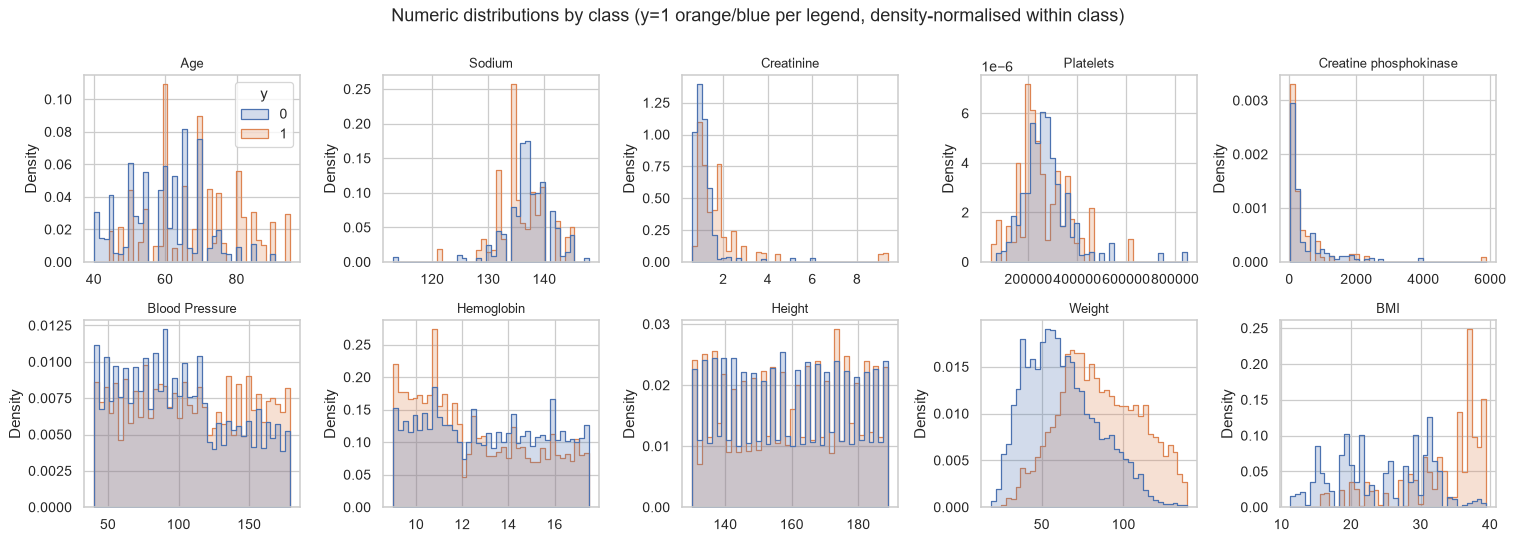

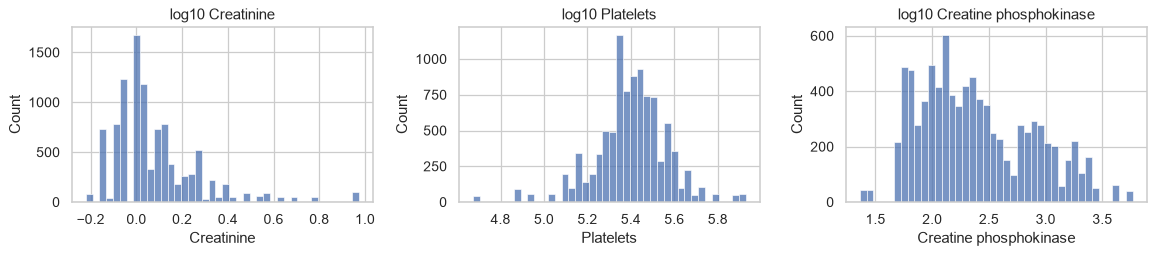

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, k in zip(axes.ravel(), NUMS_B):
    sns.histplot(data=c, x=k, hue="y", stat="density", common_norm=False, element="step", bins=40, ax=ax, legend=(k == "Age")); ax.set_title(k, fontsize=10); ax.set_xlabel("")
plt.suptitle("Numeric distributions by class (y=1 orange/blue per legend, density-normalised within class)", y=1.0); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, k in zip(axes, ["Creatinine", "Platelets", "Creatine phosphokinase"]): sns.histplot(np.log10(c[k].dropna()), bins=40, ax=ax); ax.set_title("log10 " + k)
plt.tight_layout(); plt.show()

**Observation.** Age, Sodium, Weight and BMI histograms are visibly *spiky* with gaps - a signature of a few hundred replicated patients rather than a smooth population. Creatinine and CPK have long right tails (log10 panels are much closer to symmetric). Class-conditional shapes differ for Weight, BMI (positives pile up at BMI 33-40), Age (positives older), Creatinine (tail is mostly positive) and Sodium (positives lower); Height is identical across classes.

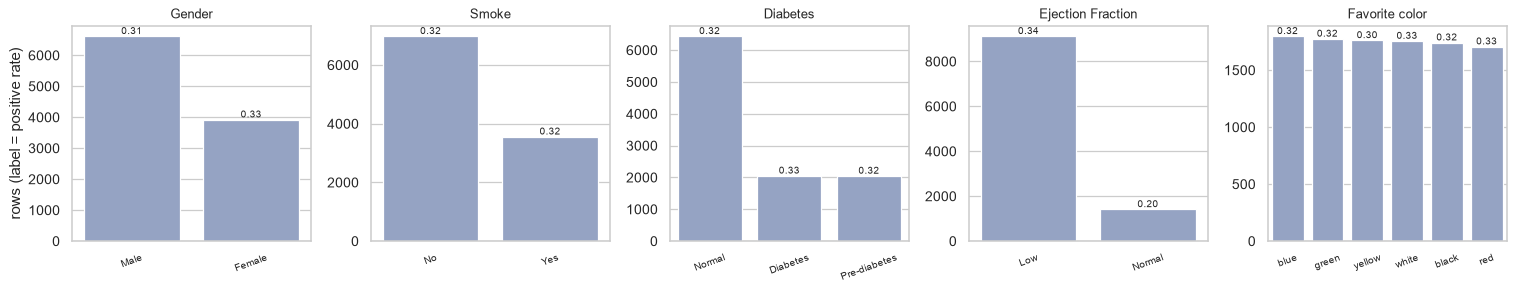

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, k in zip(axes, CATS):
    g = c.groupby(k).y.agg(["size", "mean"]).sort_values("size", ascending=False); sns.barplot(x=g.index, y=g["size"], ax=ax, color="#8da0cb")
    for i, (n, m) in enumerate(zip(g["size"], g["mean"])): ax.text(i, n, f"{m:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(k, fontsize=10); ax.set_ylabel("rows (label = positive rate)" if k == CATS[0] else ""); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8, rotation=20)
plt.tight_layout(); plt.show()

**Observation.** Gender 63/37 male, Smoke about 1/3 yes, Diabetes 61% normal, Ejection Fraction 87% Low / 13% Normal (the unlabeled `High` level is absent from train), and colour is uniform over six values. The printed positive rate above each bar is nearly flat for Gender, Smoke, Diabetes and colour (about 0.30-0.33) and clearly lower for Ejection Fraction `Normal` (about 0.20).

               feature  Pearson  Spearman  Pearson(log1p x)  |S|-|P|  Spearman cluster-CI low  Spearman cluster-CI high
                   BMI   0.5240    0.5341            0.4865   0.0101                   0.4230                    0.6351
            Creatinine   0.3021    0.4133            0.3796   0.1112                   0.2732                    0.5122
                Weight   0.4212    0.4096            0.4060  -0.0116                   0.3239                    0.4809
                   Age   0.3636    0.3302            0.3484  -0.0334                   0.1866                    0.4751
                Sodium  -0.1365   -0.1728           -0.1358   0.0363                  -0.3086                   -0.0228
            Hemoglobin  -0.1140   -0.1148           -0.1157   0.0009                  -0.2338                    0.0120
        Blood Pressure   0.0918    0.0883            0.0832  -0.0035                  -0.0269                    0.2253
             Platelets  -0.0648   -0.074

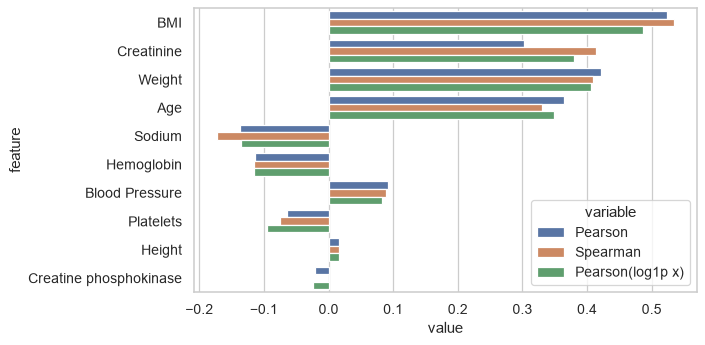

In [21]:
rows = []
for k in NUMS_B:
    s = c[k]; m = s.notna(); yy = c.y[m]; x = s[m]
    P = stats.pearsonr(x, yy)[0]; S = stats.spearmanr(x, yy)[0]; Pl = stats.pearsonr(np.log1p(x - min(0, x.min())), yy)[0]
    rows.append((k, P, S, Pl, abs(S) - abs(P)))
gcodes = c.patient.astype("category").cat.codes.values; Gn = gcodes.max() + 1; members = [np.where(gcodes == g)[0] for g in range(Gn)]; rngb = np.random.default_rng(SEED); draws = [np.concatenate([members[g] for g in rngb.integers(0, Gn, Gn)]) for _ in range(200)]
ci = {}
for k in NUMS_B:
    v = c[k].fillna(c[k].median()).values; yv = c.y.values; ss = [stats.spearmanr(v[ix], yv[ix])[0] for ix in draws]; ci[k] = (np.percentile(ss, 2.5), np.percentile(ss, 97.5))
B = pd.DataFrame(rows, columns=["feature", "Pearson", "Spearman", "Pearson(log1p x)", "|S|-|P|"])
B["Spearman cluster-CI low"] = [ci[k][0] for k in B.feature]; B["Spearman cluster-CI high"] = [ci[k][1] for k in B.feature]
B = B.sort_values("Spearman", key=abs, ascending=False)
print(B.round(4).to_string(index=False))
print("\nNote: the target is binary, so 'Pearson on log target' is undefined (log of 0/1); Pearson here is the point-biserial correlation, and the log1p column transforms the FEATURE.")
fig, ax = plt.subplots(figsize=(8, 4)); B2 = B.melt(id_vars="feature", value_vars=["Pearson", "Spearman", "Pearson(log1p x)"]); sns.barplot(data=B2, y="feature", x="value", hue="variable", ax=ax); plt.tight_layout(); plt.show()

**Observation.** Ranking by Spearman: BMI 0.534, Creatinine 0.413, Weight 0.410, Age 0.330, Sodium -0.173, Hemoglobin -0.115, Blood Pressure 0.088; Height, Platelets and CPK are about zero. The cluster-bootstrap 95% CIs (resampling patient groups) are wide - BMI [0.42, 0.64], Age [0.19, 0.48], Sodium [-0.31, -0.02], Hemoglobin [-0.23, 0.01] - because there are only 163 patients; Hemoglobin, Blood Pressure, Platelets, Height and CPK all include 0. Creatinine is the only feature with a meaningfully larger Spearman than Pearson (0.413 vs 0.302, gap 0.11), i.e. a monotonic-but-nonlinear relation masked by the heavy tail; the log1p-feature Pearson (0.380) recovers most of it, so a log transform is justified. The binary target has no log version, so the 'log-target' check is not applicable.

weak on both (|r|<0.1): ['Platelets', 'Creatine phosphokinase', 'Blood Pressure', 'Height']
               feature  R2 linear  R2 quadratic  dR2 quad  R2 decile-step  dR2 step  min decile rate  max decile rate
             Platelets     0.0042        0.0062    0.0020          0.0383    0.0341           0.1135           0.4229
Creatine phosphokinase     0.0005        0.0117    0.0113          0.0249    0.0245           0.1787           0.4310
        Blood Pressure     0.0084        0.0096    0.0012          0.0102    0.0018           0.2676           0.4047
                Height     0.0003        0.0003    0.0000          0.0008    0.0005           0.2932           0.3349


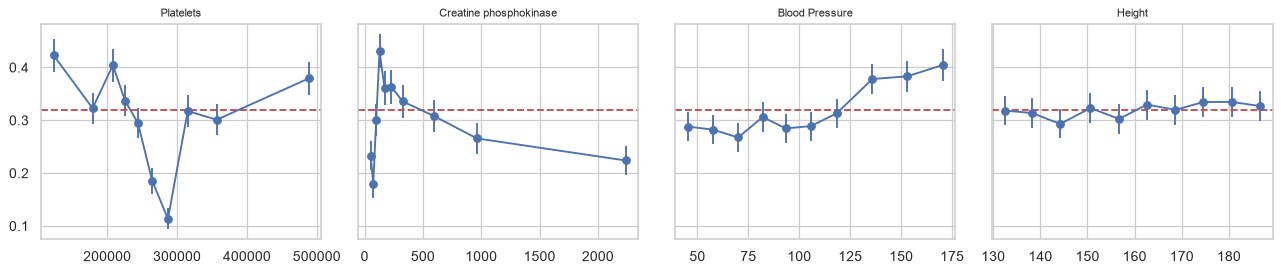

In [22]:
# Features weak on BOTH Pearson and Spearman: test for non-monotonic structure. Judge by effect size (delta R^2, spread of decile means), not p.
weak = [k for k in NUMS_B if abs(B.set_index("feature").loc[k, "Pearson"]) < 0.1 and abs(B.set_index("feature").loc[k, "Spearman"]) < 0.1]
print("weak on both (|r|<0.1):", weak)
def r2(X, y): X = np.column_stack([np.ones(len(X)), X]); b = np.linalg.lstsq(X, y, rcond=None)[0]; return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()
rows = []
for k in weak:
    m = c[k].notna(); x = c.loc[m, k].values.astype(float); y = c.y[m].values; z = (x - x.mean()) / x.std()
    lin, quad = r2(z[:, None], y), r2(np.column_stack([z, z ** 2]), y)
    dec = pd.qcut(pd.Series(x).rank(method="first"), 10, labels=False); step = r2(pd.get_dummies(dec).values.astype(float), y); means = pd.Series(y).groupby(dec.values).mean()
    rows.append((k, lin, quad, quad - lin, step, step - lin, means.min(), means.max()))
N = pd.DataFrame(rows, columns=["feature", "R2 linear", "R2 quadratic", "dR2 quad", "R2 decile-step", "dR2 step", "min decile rate", "max decile rate"]); print(N.round(4).to_string(index=False))
fig, axes = plt.subplots(1, len(weak), figsize=(3.6 * len(weak), 3.2), sharey=True)
for ax, k in zip(np.atleast_1d(axes), weak):
    m = c[k].notna(); d_ = pd.DataFrame({"x": c.loc[m, k].values, "y": c.y[m].values}); d_["bin"] = pd.qcut(d_.x.rank(method="first"), 10, labels=False)
    g = d_.groupby("bin").agg(x=("x", "mean"), p=("y", "mean"), n=("y", "size")); se = np.sqrt(g.p * (1 - g.p) / g.n)
    ax.errorbar(g.x, g.p, 1.96 * se, marker="o"); ax.axhline(c.y.mean(), c="r", ls="--"); ax.set_title(k, fontsize=9)
plt.tight_layout(); plt.show()

**Observation.** Four features are weak on both coefficients (Platelets, CPK, Blood Pressure, Height). Decile-step R2 beats linear R2 by 0.034 for Platelets and 0.025 for CPK, by only 0.0018 for Blood Pressure and 0.0005 for Height. The Platelets profile dips to 0.11 near 270-300k and is about 0.4 at both ends; CPK peaks at 0.43 near 100-150 and declines; Blood Pressure steps up from about 0.28 to 0.40 above 120; Height is flat. By effect size these are small (the best ΔR2 is 3% of the variance). Because rows of a patient move together and only about 160 patients exist, the U-shapes are as likely to be a few patients' idiosyncrasies as real physiology; they are hypotheses, not findings.

In [23]:
rows = []
for k in CATS:
    groups = [g.y.values for _, g in c.groupby(k)]; F, pF = stats.f_oneway(*groups); H, pH = stats.kruskal(*groups)
    gm = c.groupby(k).y.transform("mean"); eta2 = ((gm - c.y.mean()) ** 2).sum() / ((c.y - c.y.mean()) ** 2).sum()
    rows.append((k, len(groups), F, pF, H, pH, eta2))
CA = pd.DataFrame(rows, columns=["feature", "levels", "ANOVA F", "p (ANOVA)", "Kruskal H", "p (KW)", "eta^2"]).sort_values("eta^2", ascending=False)
pd.set_option("display.float_format", lambda v: f"{v:.5g}"); print(CA.to_string(index=False))

          feature  levels  ANOVA F  p (ANOVA)  Kruskal H     p (KW)      eta^2
Ejection Fraction       2   107.63 4.2764e-25     106.55 5.5785e-25   0.010105
   Favorite color       6   1.1241    0.34497     5.6203    0.34493 0.00053299
           Gender       2   2.2454    0.13404     2.2451    0.13404 0.00021291
         Diabetes       3   0.9011    0.40615     1.8022    0.40611 0.00017091
            Smoke       2  0.52411    0.46911    0.52413    0.46908 4.9704e-05


**Observation.** Only Ejection Fraction has a real association: eta2 = 0.010 (1% of target variance), ANOVA F = 108, Kruskal H = 107. Favorite color (eta2 0.0005), Gender (0.0002), Diabetes (0.0002) and Smoke (0.00005) are essentially zero, with p between 0.13 and 0.47. Even the EF p-value (1e-25) is anti-conservative because rows are not independent; the effect size, 1%, is the honest number.

In [24]:
rng = np.random.default_rng(SEED); base = c.y.mean(); res = []
gi = c.patient.astype("category").cat.codes.values; G = gi.max() + 1
def cboot(mask, B=1000, other=None):
    """Patient-cluster bootstrap: resample patient groups, recompute the level's rate (or its difference to `other`)."""
    def cnt(msk): return np.bincount(gi[msk], minlength=G), np.bincount(gi[msk], weights=c.y.values[msk], minlength=G)
    n1, s1 = cnt(mask); n2, s2 = cnt(other) if other is not None else (None, None); out = []
    for _ in range(B):
        w = np.bincount(rng.integers(0, G, G), minlength=G); r1 = (w * s1).sum() / max((w * n1).sum(), 1)
        out.append(r1 - (w * s2).sum() / max((w * n2).sum(), 1) if other is not None else r1)
    return np.array(out)
for k in CATS:
    for lvl, g in c.groupby(k):
        yy = g.y.values; boots = cboot((c[k] == lvl).values)
        res.append((k, lvl, len(yy), yy.mean(), (yy.mean() - base) * 100, (yy.mean() / base - 1) * 100, np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
E = pd.DataFrame(res, columns=["feature", "level", "n", "rate", "diff vs overall (pp)", "relative diff %", "cluster CI low", "cluster CI high"]); print(E.round(3).to_string(index=False))
print("\nExtremes per feature (only levels with n>=100), Cohen's d on the 0/1 target, PATIENT-CLUSTER bootstrap CI of the difference, Tukey HSD (row-level Tukey p-values are anti-conservative because rows of one patient are not independent):")
for k in CATS:
    e = E[(E.feature == k) & (E.n >= 100)].sort_values("rate"); lo, hi = e.iloc[0], e.iloc[-1]
    a, b = c.y[c[k] == lo.level].values, c.y[c[k] == hi.level].values
    d = (b.mean() - a.mean()) / np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    dif = cboot((c[k] == hi.level).values, other=(c[k] == lo.level).values)
    th = stats.tukey_hsd(*[g.y.values for _, g in c.groupby(k)]); levels = list(c.groupby(k).groups)
    sig = [(levels[i], levels[j], round(th.pvalue[i, j], 4)) for i in range(len(levels)) for j in range(i + 1, len(levels)) if th.pvalue[i, j] < 0.05]
    print(f"{k:18s} {lo.level} {lo.rate:.3f} -> {hi.level} {hi.rate:.3f} | diff {np.mean(dif)*100:+.1f}pp CI [{np.percentile(dif,2.5)*100:+.1f},{np.percentile(dif,97.5)*100:+.1f}] | d={d:.3f} | Tukey p<.05 pairs: {sig}")
pd.reset_option("display.float_format")

          feature        level    n  rate  diff vs overall (pp)  relative diff %  cluster CI low  cluster CI high
           Gender       Female 3926 0.329                 0.884            2.764           0.229            0.441
           Gender         Male 6620 0.315                -0.524           -1.639           0.228            0.402
            Smoke           No 6985 0.317                -0.235           -0.734           0.245             0.39
            Smoke          Yes 3561 0.324                 0.461             1.44           0.212            0.437
         Diabetes     Diabetes 2055 0.331                 1.116             3.49           0.226            0.435
         Diabetes       Normal 6440 0.315                -0.437           -1.367            0.23            0.409
         Diabetes Pre-diabetes 2051 0.322                 0.254            0.794           0.223             0.43
Ejection Fraction          Low 9127 0.338                 1.849            5.781        

Diabetes           Normal 0.315 -> Diabetes 0.331 | diff +1.7pp CI [-10.9,+15.1] | d=0.033 | Tukey p<.05 pairs: []
Ejection Fraction  Normal 0.201 -> Low 0.338 | diff +13.6pp CI [-3.4,+29.3] | d=0.296 | Tukey p<.05 pairs: [('Low', 'Normal', np.float64(0.0))]


Favorite color     yellow 0.298 -> red 0.334 | diff +3.6pp CI [+0.8,+6.6] | d=0.076 | Tukey p<.05 pairs: []


**Observation.** The extremes: EF Normal 20.1% vs Low 33.8% (diff +13.6 pp, Cohen d = 0.30, **cluster CI [-3.4, +29.3] pp - includes 0** even though row-level Tukey gives p < 0.001). Colour yellow 29.8% vs red 33.4% (d = 0.08), Smoke, Diabetes and Gender differences are all about 1-2 pp with d <= 0.03 and cluster CIs of roughly +-13 pp. Row-level Tukey flags only EF Low-Normal. Conclusion: no categorical feature has a reliable effect once the replicated patients are accounted for; EF is the only candidate, and it is at best a small effect.

       A                 B  R2 additive  R2 full  interaction dR2         F       p
  Gender             Smoke      0.00045  0.01902          0.01857 199.57424 0.00000
  Gender          Diabetes      0.00034  0.00731          0.00697  37.00632 0.00000
  Gender Ejection Fraction      0.01069  0.01161          0.00092   9.79614 0.00175
   Smoke          Diabetes      0.00026  0.01815          0.01789  96.03862 0.00000
   Smoke Ejection Fraction      0.01014  0.01057          0.00042   4.51359 0.03365
Diabetes Ejection Fraction      0.01037  0.01256          0.00219  11.70290 0.00001


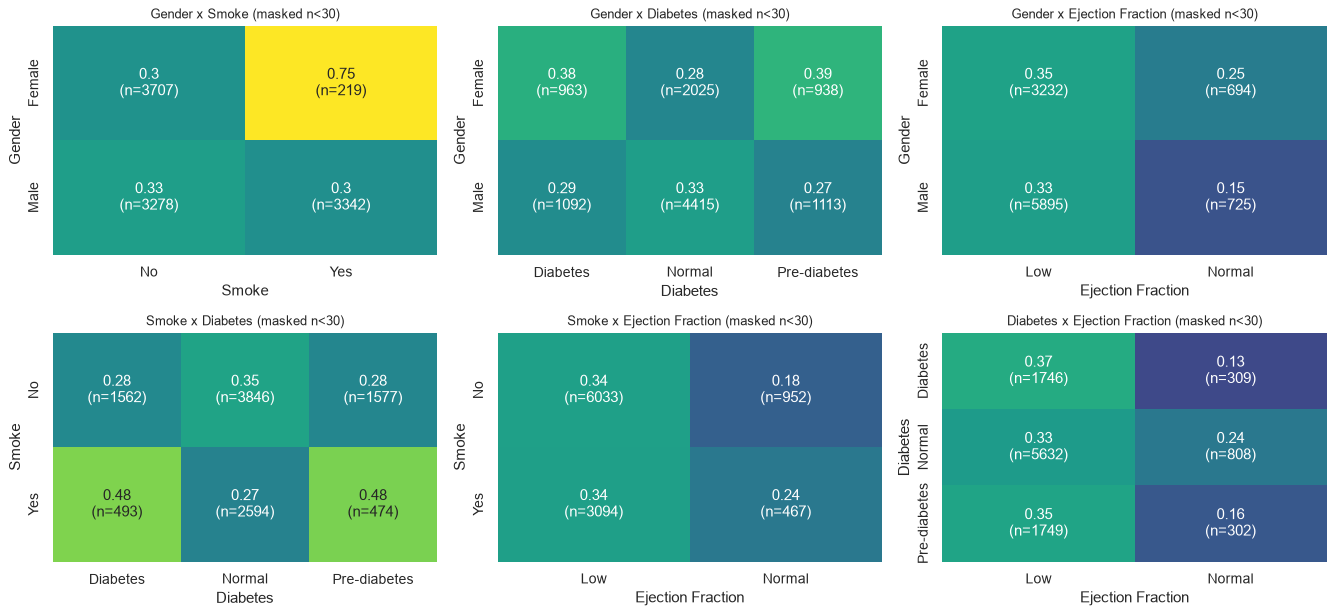

In [25]:
import itertools
C4 = ["Gender", "Smoke", "Diabetes", "Ejection Fraction"]
def design(df, cols, inter):
    X = [np.ones(len(df))]
    for k in cols: X += [(df[k] == l).astype(float).values for l in sorted(df[k].unique())[1:]]
    if inter:
        a, b = cols; la, lb = sorted(df[a].unique())[1:], sorted(df[b].unique())[1:]
        X += [((df[a] == i) & (df[b] == j)).astype(float).values for i in la for j in lb]
    return np.column_stack(X)
def ols_rss(X, y): b = np.linalg.lstsq(X, y, rcond=None)[0]; return ((y - X @ b) ** 2).sum()
rows = []
for a, b in itertools.combinations(C4, 2):
    y = c.y.values; Xa, Xf = design(c, [a, b], False), design(c, [a, b], True); r_a, r_f = ols_rss(Xa, y), ols_rss(Xf, y); tss = ((y - y.mean()) ** 2).sum()
    df1, df2 = Xf.shape[1] - Xa.shape[1], len(y) - Xf.shape[1]; F = ((r_a - r_f) / df1) / (r_f / df2)
    rows.append((a, b, 1 - r_a / tss, 1 - r_f / tss, (r_a - r_f) / tss, F, stats.f.sf(F, df1, df2)))
IR = pd.DataFrame(rows, columns=["A", "B", "R2 additive", "R2 full", "interaction dR2", "F", "p"]); print(IR.round(5).to_string(index=False))
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (a, b) in zip(axes.ravel(), itertools.combinations(C4, 2)):
    m = c.pivot_table(index=a, columns=b, values="y", aggfunc="mean"); n = c.pivot_table(index=a, columns=b, values="y", aggfunc="size")
    ann = m.round(2).astype(str) + "\n(n=" + n.astype("Int64").astype(str) + ")"
    sns.heatmap(m.where(n >= 30), annot=ann.where(n >= 30, "n<30"), fmt="", cmap="viridis", vmin=0, vmax=0.6, ax=ax, cbar=False); ax.set_title(f"{a} x {b} (masked n<30)", fontsize=10)
plt.tight_layout(); plt.show()

**Observation.** Row-level two-way interaction ΔR2 is largest for Gender x Smoke (0.0186, F = 200) and Smoke x Diabetes (0.0179, F = 96), while the additive models explain almost nothing (R2 <= 0.0004 for those pairs). F-tests are meaningless here (they treat 10,546 replicated rows as independent), and the heatmaps show why the effect needs scrutiny: the striking cells are female smokers and smokers with diabetes. The next cell counts how many patients stand behind them.

                   n   rate     BMI     Age  Creatinine   Sodium
grp                                                             
Female smoker    219  0.749  33.930  63.616         1.7  136.329
everyone else  10327  0.311  26.751  62.362         1.1  136.781
patient groups contributing to the Female-smoker cell: 4 | distinct Smoke values per patient group (mean): 1.12
                 mean                         size                    
Diabetes     Diabetes Normal Pre-diabetes Diabetes Normal Pre-diabetes
Gender Smoke                                                          
Female No       0.345  0.263        0.349      913   1914          880
       Yes      1.000  0.505        1.000       50    111           58
Male   No       0.194  0.434        0.182      649   1932          697
       Yes      0.427  0.255        0.406      443   2483          416


observed rate gap (pp): 43.8 | permutation null 99.9th percentile of the gap (pp): 68.0 | p<1/2000: False
                mean                  size                
bmi_t            low    mid   high     low     mid    high
grp                                                       
Female smoker    NaN  1.000  0.696     NaN    38.0   181.0
everyone else  0.084  0.221  0.644  3519.0  3480.0  3328.0


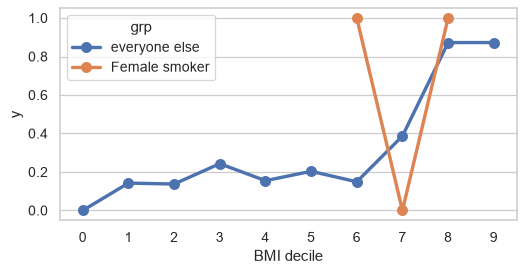

In [26]:
# INVESTIGATION 4: Gender x Smoke shows a huge interaction (female smokers ~75% positive). A striking cell is a hypothesis until checked: size, confounding, and a permutation test.
c["grp"] = np.where((c.Gender == "Female") & (c.Smoke == "Yes"), "Female smoker", "everyone else")
print(c.groupby("grp").agg(n=("y", "size"), rate=("y", "mean"), BMI=("BMI", "mean"), Age=("Age", "mean"), Creatinine=("Creatinine", "median"), Sodium=("Sodium", "mean")).round(3))
print("patient groups contributing to the Female-smoker cell:", c.loc[c.grp == "Female smoker", "patient"].nunique(), "| distinct Smoke values per patient group (mean):", round(c.groupby("patient").Smoke.nunique().mean(), 2))
t3 = c.pivot_table(index=["Gender", "Smoke"], columns="Diabetes", values="y", aggfunc=["mean", "size"]); print(t3.round(3))
obs = c.y[c.grp == "Female smoker"].mean() - c.y[c.grp != "Female smoker"].mean(); rng = np.random.default_rng(SEED); k = (c.grp == "Female smoker").sum(); gm = c.groupby("patient").y.agg(["sum", "size"]); null = []
for _ in range(2000):   # GROUP-level null: pick random whole patient groups until the same number of rows, compare their positive rate with the base rate
    sel = gm.sample(frac=1, random_state=int(rng.integers(0, 1e9))); sel = sel[sel["size"].cumsum() <= k]; null.append(sel["sum"].sum() / sel["size"].sum() - c.y.mean())
print("observed rate gap (pp):", round(obs * 100, 1), "| permutation null 99.9th percentile of the gap (pp):", round(np.percentile(null, 99.9) * 100, 1), "| p<1/2000:", obs > max(null))
# is it explained by BMI/Age/Creatinine? compare positive rate inside BMI terciles
c["bmi_t"] = pd.qcut(c.BMI, 3, labels=["low", "mid", "high"]); print(c.pivot_table(index="grp", columns="bmi_t", values="y", aggfunc=["mean", "size"], observed=True).round(3))
fig, ax = plt.subplots(figsize=(6, 3.2)); sns.pointplot(data=c.assign(dec=pd.qcut(c.BMI, 10, labels=False)), x="dec", y="y", hue="grp", ax=ax, errorbar=None); ax.set_xlabel("BMI decile"); plt.tight_layout(); plt.show()

**Observation (investigation).** The Female-smoker cell has 219 rows and a 74.9% positive rate versus 31.1% for everyone else (gap +43.8 pp), and 100% positive among those with Diabetes/Pre-diabetes. But those 219 rows come from only **4 patient groups**. A group-level null (random whole patient groups of the same row count) gives a 99.9th percentile gap of 68 pp, so the observed 43.8 pp is *not* distinguishable from sampling a handful of patients; the printed verdict is `p<1/2000: False`. The cell is also confounded: its BMI averages 33.9 vs 26.8 (the strongest predictor). This is a hypothesis generated by four replicated patients, not a finding, and is not used for feature engineering.

heavy-tailed or >3% IQR outliers: ['Creatinine', 'Platelets', 'Creatine phosphokinase']
               feature  n extreme  % extreme  y-rate extreme  y-rate typical  rank-biserial (extreme vs typical)   p  n low-tail  n high-tail
            Creatinine        825        7.8          0.7152          0.2970                              0.4182 0.0           0          825
             Platelets        308        2.9          0.1818          0.3121                             -0.1303 0.0           0          308
Creatine phosphokinase        848        8.0          0.2335          0.3072                             -0.0737 0.0           0          848


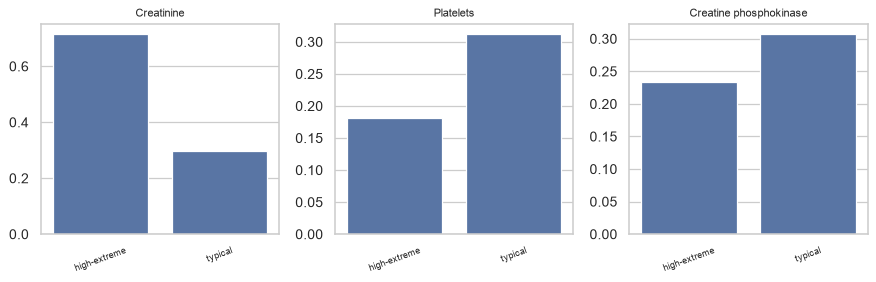

In [27]:
heavy = [k for k in NUMS_B if abs(c[k].skew()) > 1 or iqr_out(c[k]) > 3]; print("heavy-tailed or >3% IQR outliers:", heavy)
rows = []
for k in heavy:
    s = c[k]; q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    ext = (s < lo) | (s > hi); a, b = c.y[ext], c.y[~ext & s.notna()]
    if ext.sum() > 0:
        U, p = stats.mannwhitneyu(a, b); rows.append((k, int(ext.sum()), round(ext.mean() * 100, 1), a.mean(), b.mean(), 1 - 2 * U / (len(a) * len(b)) * 1.0, p, int((s < lo).sum()), int((s > hi).sum())))
O = pd.DataFrame(rows, columns=["feature", "n extreme", "% extreme", "y-rate extreme", "y-rate typical", "rank-biserial (extreme vs typical)", "p", "n low-tail", "n high-tail"]); O["rank-biserial (extreme vs typical)"] *= -1   # positive = extremes have higher y
print(O.round(4).to_string(index=False))
fig, axes = plt.subplots(1, len(heavy), figsize=(3.3 * len(heavy), 3.3))
for ax, k in zip(np.atleast_1d(axes), heavy):
    s = c[k]; q1, q3 = s.quantile([.25, .75]); i = q3 - q1; cat = np.where(s < q1 - 1.5 * i, "low-extreme", np.where(s > q3 + 1.5 * i, "high-extreme", "typical")); cat = pd.Series(cat, index=c.index)[s.notna()]
    g = c.y[s.notna()].groupby(cat).mean(); sns.barplot(x=g.index, y=g.values, ax=ax); ax.set_title(k, fontsize=9); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=7, rotation=20)
plt.tight_layout(); plt.show()

**Observation.** Creatinine extremes (825 rows, 7.8%, all high-tail) are positive 71.5% of the time versus 29.7% for typical rows (rank-biserial 0.42, a large effect): the outliers *are* the signal and must not be removed or aggressively winsorised. Platelets extremes (2.9%) are positive 18.2% vs 31.2% (rank-biserial -0.13) and CPK extremes (8.0%) 23.4% vs 30.7% (-0.07): small effects in the opposite direction. The bar charts show the same ordering. Verdict: keep all rows; clip only at very wide quantiles (0.5%/99.5%) learned on train, and log-transform Creatinine and CPK.

In [28]:
# The target is binary, so "the target's own extremes" = the minority class: profile y=1 vs y=0 on every feature (standardised mean difference, Mann-Whitney).
rows = []
for k in NUMS_B:
    a, b = c.loc[c.y == 1, k].dropna(), c.loc[c.y == 0, k].dropna(); sp = np.sqrt((a.var() * (len(a) - 1) + b.var() * (len(b) - 1)) / (len(a) + len(b) - 2))
    rows.append((k, a.median(), b.median(), (a.mean() - b.mean()) / sp, 1 - 2 * stats.mannwhitneyu(a, b)[0] / (len(a) * len(b))))
TP = pd.DataFrame(rows, columns=["feature", "median y=1", "median y=0", "Cohen d", "rank-biserial (neg: y=1 higher)"]).sort_values("Cohen d", key=abs, ascending=False); print(TP.round(3).to_string(index=False))
q = c.assign(bmi_dec=pd.qcut(c.BMI, 10, labels=False)).groupby("bmi_dec").y.agg(["mean", "size"]); print("\npositive rate by BMI decile:", q["mean"].round(3).tolist())

               feature  median y=1  median y=0  Cohen d  rank-biserial (neg: y=1 higher)
                   BMI      35.672      25.071    1.319                           -0.661
                Weight      82.000      59.000    0.996                           -0.507
                   Age      70.000      60.000    0.837                           -0.408
            Creatinine       1.400       1.000    0.673                           -0.505
                Sodium     135.000     137.000   -0.295                            0.213
            Hemoglobin      11.800      13.000   -0.246                            0.142
        Blood Pressure     107.000      97.000    0.198                           -0.109
             Platelets  235000.000  262000.000   -0.141                            0.094
Creatine phosphokinase     176.000     197.000   -0.046                           -0.001
                Height     160.000     159.000    0.034                           -0.020

positive rate by BMI

**Observation.** The positive class (y=1) is much heavier (median BMI 35.7 vs 25.1, Cohen d 1.32; Weight 82 vs 59, d 1.00), older (70 vs 60, d 0.84), has higher Creatinine (1.4 vs 1.0, d 0.67), lower Sodium (135 vs 137, d -0.30) and lower Hemoglobin (d -0.25); Height and CPK show no difference. The BMI-decile positive rates are 0, 0.14, 0.14, 0.24, 0.16, 0.20, 0.19, 0.37, 0.89, 0.87: a sharp jump above BMI of about 33 with zig-zags below it (single patients), not a smooth gradient.

In [29]:
from sklearn.feature_selection import mutual_info_classif
f = pd.DataFrame(index=c.index)
imp = c[NUMS_B].fillna(c[NUMS_B].median())
for k in NUMS_B: f[k] = imp[k]
f["BMI_sq"] = imp.BMI ** 2; f["Age_x_BMI"] = imp.Age * imp.BMI; f["Creat_per_Sodium"] = imp.Creatinine / imp.Sodium; f["Weight_per_Height"] = imp.Weight / imp.Height
f["log_Creatinine"] = np.log1p(imp.Creatinine); f["log_CPK"] = np.log1p(imp["Creatine phosphokinase"])
f["Age>=70"] = (imp.Age >= 70).astype(int); f["BMI>=33"] = (imp.BMI >= 33).astype(int); f["Creatinine>=1.5"] = (imp.Creatinine >= 1.5).astype(int); f["Sodium<136"] = (imp.Sodium < 136).astype(int)
f["Creatinine_missing"] = c.Creatinine.isna().astype(int); f["Platelets_sentinel"] = c.Platelets.isna().astype(int); f["CPK_sentinel"] = c["Creatine phosphokinase"].isna().astype(int)
mi = mutual_info_classif(f.values, c.y.values, random_state=SEED, n_neighbors=5)
FE = pd.DataFrame({"feature": f.columns, "Pearson": [np.corrcoef(f[k], c.y)[0, 1] for k in f], "Spearman": [stats.spearmanr(f[k], c.y)[0] for k in f], "MI": mi}).set_index("feature")
parent = {"BMI": "Weight", "BMI_sq": "BMI", "Age_x_BMI": "BMI", "Creat_per_Sodium": "Creatinine", "Weight_per_Height": "Weight", "log_Creatinine": "Creatinine", "log_CPK": "Creatine phosphokinase", "Age>=70": "Age", "BMI>=33": "BMI", "Creatinine>=1.5": "Creatinine", "Sodium<136": "Sodium"}
FE["parent"] = [parent.get(k, "") for k in FE.index]; FE["beats parent (|Spearman| and MI)"] = [(abs(FE.Spearman[k]) > abs(FE.Spearman[p]) and FE.MI[k] > FE.MI[p]) if p else "" for k, p in zip(FE.index, FE.parent)]
FE["rank by MI"] = FE.MI.rank(ascending=False).astype(int); print(FE.sort_values("MI", ascending=False).round(4).to_string())

                        Pearson  Spearman      MI                  parent beats parent (|Spearman| and MI)  rank by MI
feature                                                                                                               
log_CPK                 -0.0288   -0.0025  0.4776  Creatine phosphokinase                            False           1
Creatine phosphokinase  -0.0343   -0.0025  0.4691                                                                    2
Creat_per_Sodium         0.3041    0.4022  0.4358              Creatinine                            False           3
Age_x_BMI                0.5854    0.5636  0.4016                     BMI                             True           4
Platelets               -0.0644   -0.0757  0.3957                                                                    5
BMI                      0.5240    0.5341  0.3606                  Weight                             True           6
BMI_sq                   0.5551    0.5341  0.359

**Observation.** `Age_x_BMI` (Spearman 0.564, Pearson 0.585) beats its parent BMI (0.534) on both coefficients and MI, so it earns a place; `BMI_sq` (Pearson 0.555) and `BMI>=33` (0.618) add a little linear signal over BMI (0.524) but not rank signal; `BMI` itself beats Weight; `log_Creatinine` raises Pearson 0.305 to 0.382 without changing Spearman (0.406); `Creat_per_Sodium` (0.402) does not beat Creatinine on Spearman; `Creatinine>=1.5` has Pearson 0.443, higher than raw Creatinine's 0.305, because it captures the high-tail step. `Weight_per_Height` (0.485) is below BMI. The flags `Creatinine_missing`, `CPK_sentinel`, `Platelets_sentinel` are weak linearly (|r| 0.08-0.13) and suspect for the reasons above. The MI column ranks `log_CPK` first (0.48), which looks wrong given a Spearman of -0.003: the next cell investigates.

In [30]:
# INVESTIGATION 5: mutual information ranks Creatine phosphokinase and Platelets at the TOP while Pearson/Spearman are ~0. Real non-linear signal, or an artefact of the kNN estimator on tied (median-imputed) values?
from sklearn.metrics import mutual_info_score
rows = []
for k in ["Creatine phosphokinase", "Platelets", "Blood Pressure", "Hemoglobin", "Height", "Creatinine", "BMI"]:
    x = imp[k].values; xj = x + np.random.default_rng(SEED).normal(0, 1e-6 * x.std(), len(x))
    binned = pd.qcut(pd.Series(x).rank(method="first"), 20, labels=False).values
    rows.append((k, mutual_info_classif(x[:, None], c.y.values, random_state=SEED)[0], mutual_info_classif(xj[:, None], c.y.values, random_state=SEED)[0], mutual_info_score(binned, c.y.values), (x == np.median(x)).mean()))
M = pd.DataFrame(rows, columns=["feature", "kNN MI (tied)", "kNN MI (jittered)", "plug-in MI (20 quantile bins)", "share tied at median"]); print(M.round(4).to_string(index=False))
ok = c["Creatine phosphokinase"].notna()
print("\nkNN MI of CPK on its own non-sentinel rows only:", round(mutual_info_classif(c.loc[ok, ["Creatine phosphokinase"]].values, c.y[ok].values, random_state=SEED)[0], 4))
print("distinct CPK values:", c["Creatine phosphokinase"].nunique(), "| share of exact-CPK-value groups with a single outcome:", round(float(c.groupby("Creatine phosphokinase").y.agg(lambda s: s.nunique() == 1).mean()), 3), "-> each exact CPK value is close to a patient identifier")
print("shuffled-y kNN MI for CPK (should be ~0):", round(mutual_info_classif(imp[["Creatine phosphokinase"]].values, np.random.default_rng(1).permutation(c.y.values), random_state=SEED)[0], 4))

               feature  kNN MI (tied)  kNN MI (jittered)  plug-in MI (20 quantile bins)  share tied at median
Creatine phosphokinase         0.4717             0.4741                         0.0371                0.1728
             Platelets         0.4015             0.3969                         0.0456                0.1058
        Blood Pressure         0.0030             0.0037                         0.0056                0.0081
            Hemoglobin         0.0072             0.0085                         0.0076                0.0104
                Height         0.0010             0.0016                         0.0008                0.0176
            Creatinine         0.2299             0.2351                         0.1608                0.1460
                   BMI         0.3592             0.3624                         0.2470                0.0008

kNN MI of CPK on its own non-sentinel rows only: 0.5632
distinct CPK values: 159 | share of exact-CPK-value groups with

**Observation (investigation).** The kNN MI for CPK (0.47) and Platelets (0.40) is not caused by the median-imputation ties: jittering changes nothing (0.474, 0.397), and restricting to CPK's own non-sentinel rows *raises* it to 0.563, while shuffled-y MI is about 0 (0.0045). The coarse 20-bin plug-in MI is only 0.037 / 0.046. The reason is identifiability: there are only 159 distinct CPK values among the train rows and 96.9% of them are linked to a single outcome, so CPK works as a **fingerprint of the replicated patient**, and the kNN estimator, which sees exact neighbours, reads that as huge information. In a patient-grouped evaluation this information is not transferable. This is the same leakage as in `leakage_groups`, seen through a different column. `CPK` (and, to a lesser extent, `Platelets`) are therefore not trustworthy as ordinary predictors; MI cannot be used to rank features in this file.

tree depth -> CV accuracy, random : {1: np.float64(0.837), 2: np.float64(0.874), 3: np.float64(0.91), 4: np.float64(0.936), 5: np.float64(0.955), 6: np.float64(0.974), 7: np.float64(0.983), 8: np.float64(0.99), 9: np.float64(0.994), 10: np.float64(0.995), 11: np.float64(0.998), 12: np.float64(0.999), 13: np.float64(0.999), 14: np.float64(0.999)}
tree depth -> CV accuracy, grouped: {1: np.float64(0.825), 2: np.float64(0.851), 3: np.float64(0.839), 4: np.float64(0.835), 5: np.float64(0.839), 6: np.float64(0.824), 7: np.float64(0.814), 8: np.float64(0.812), 9: np.float64(0.813), 10: np.float64(0.818), 11: np.float64(0.8), 12: np.float64(0.806), 13: np.float64(0.806), 14: np.float64(0.806)}


{'naive accuracy': 0.6803, 'HGB ROC AUC (random)': 1.0, 'HGB PR AUC (random)': 0.9999, 'Logistic ROC AUC (random)': 0.893, 'HGB ROC AUC (grouped)': 0.8137, 'HGB PR AUC (grouped)': 0.7004, 'Logistic ROC AUC (grouped)': 0.852}


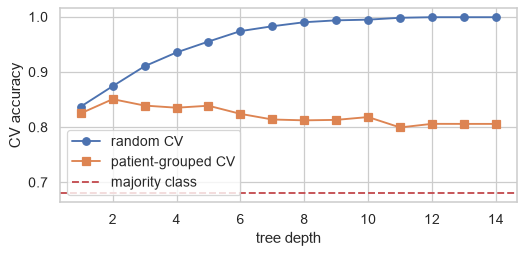

In [31]:
# INVESTIGATION 1: how predictable is y? Compare random CV with PATIENT-GROUPED CV inside the TRAIN split (random CV is contaminated by replicated patients).
from sklearn.model_selection import cross_val_score, StratifiedKFold, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
Xn = imp.copy(); Xn = Xn.join(pd.get_dummies(c[["Gender", "Smoke", "Diabetes", "Ejection Fraction"]], dtype=float)); yy = c.y.values
cvr, cvg = StratifiedKFold(5, shuffle=True, random_state=SEED), StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
depths = list(range(1, 15)); acc_r = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), Xn, yy, cv=cvr, scoring="accuracy").mean() for d in depths]
acc_g = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), Xn, yy, cv=cvg, groups=c.patient, scoring="accuracy").mean() for d in depths]
print("tree depth -> CV accuracy, random :", dict(zip(depths, np.round(acc_r, 3))))
print("tree depth -> CV accuracy, grouped:", dict(zip(depths, np.round(acc_g, 3))))
res = {"naive accuracy": 1 - yy.mean()}
for nm, cv_, kw in (("random", cvr, {}), ("grouped", cvg, {"groups": c.patient})):
    res[f"HGB ROC AUC ({nm})"] = cross_val_score(HistGradientBoostingClassifier(random_state=SEED), Xn, yy, cv=cv_, scoring="roc_auc", **kw).mean()
    res[f"HGB PR AUC ({nm})"] = cross_val_score(HistGradientBoostingClassifier(random_state=SEED), Xn, yy, cv=cv_, scoring="average_precision", **kw).mean()
    res[f"Logistic ROC AUC ({nm})"] = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xn, yy, cv=cv_, scoring="roc_auc", **kw).mean()
print({k: round(float(v), 4) for k, v in res.items()})
plt.figure(figsize=(6, 3)); plt.plot(depths, acc_r, marker="o", label="random CV"); plt.plot(depths, acc_g, marker="s", label="patient-grouped CV"); plt.axhline(1 - yy.mean(), c="r", ls="--", label="majority class"); plt.xlabel("tree depth"); plt.ylabel("CV accuracy"); plt.legend(); plt.tight_layout(); plt.show()

**Observation (investigation).** Random CV accuracy of a decision tree climbs steadily with depth to 0.999 (depth 12), a memorisation curve; patient-grouped CV peaks at **0.851 at depth 2** and then *declines* to about 0.81, the classic overfitting signature. Likewise HGB ROC AUC is 1.000 under random CV and 0.814 under grouped CV (PR AUC 0.9999 vs 0.700), and Logistic goes 0.893 to 0.852. The simple linear model is therefore as good as the flexible ones on unseen patients. Expected ceiling on unseen patients: ROC AUC about 0.81-0.89, accuracy about 0.85 against a 0.68 baseline, and a PR AUC of about 0.70 for HGB (the only PR AUC measured under grouped CV here), with large uncertainty from only about 160 training patients.

distinct patient groups per grid cell: median 1.0 | cells containing a single patient group: 74 of 138
grid cells: 138 | cells with >=95% one class: 129 | share of rows in such cells: 0.831


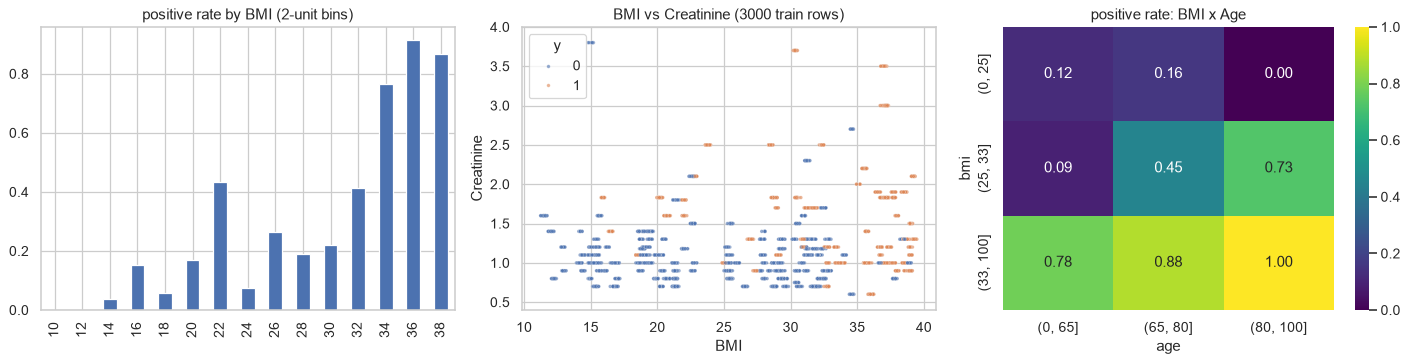

In [32]:
# INVESTIGATION 2: what does the near-deterministic structure look like? Purity of rule-like cells on (BMI, Creatinine, Age, Sodium) bins.
b = pd.DataFrame({"BMI": pd.cut(c.BMI, [0, 19, 25, 30, 33, 36, 100]), "Cr": pd.cut(imp.Creatinine, [0, 0.9, 1.2, 1.55, 100]), "Age": pd.cut(c.Age, [0, 50, 65, 80, 100]), "Na": pd.cut(c.Sodium, [0, 135, 137, 200])})
cell = pd.concat([b, c.y], axis=1).groupby(list(b.columns), observed=True).y.agg(["mean", "size"]); cell = cell[cell["size"] >= 1]
pure = ((cell["mean"] <= 0.05) | (cell["mean"] >= 0.95)); npat = pd.concat([b, c.patient], axis=1).groupby(list(b.columns), observed=True).patient.nunique(); print("distinct patient groups per grid cell: median", float(npat.median()), "| cells containing a single patient group:", int((npat == 1).sum()), "of", len(npat))
print("grid cells:", len(cell), "| cells with >=95% one class:", int(pure.sum()), "| share of rows in such cells:", round(cell.loc[pure, "size"].sum() / cell["size"].sum(), 3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
g = c.assign(bmi=pd.cut(c.BMI, np.arange(10, 42, 2))).groupby("bmi", observed=True).y.mean(); g.index = [f"{i.left:.0f}" for i in g.index]; g.plot(kind="bar", ax=axes[0]); axes[0].set_title("positive rate by BMI (2-unit bins)")
s = c.sample(3000, random_state=SEED); sns.scatterplot(data=s, x="BMI", y="Creatinine", hue="y", s=8, alpha=.6, ax=axes[1]); axes[1].set_ylim(0.4, 4); axes[1].set_title("BMI vs Creatinine (3000 train rows)")
m = c.assign(bmi=pd.cut(c.BMI, [0, 25, 33, 100]), age=pd.cut(c.Age, [0, 65, 80, 100])).pivot_table(index="bmi", columns="age", values="y", aggfunc="mean", observed=True); sns.heatmap(m, annot=True, fmt=".2f", ax=axes[2], cmap="viridis"); axes[2].set_title("positive rate: BMI x Age")
plt.tight_layout(); plt.show()

**Observation (investigation).** In the coarse BMI x Creatinine x Age x Sodium grid, 129 of 138 cells (83% of rows) are at least 95% one class, which looks like determinism, but the median cell contains **one patient group** and 74 of the 138 cells contain a single patient. Purity is therefore replication, not a rule. What *is* real is visible in the panels: the positive rate jumps above BMI of about 33, rises with age inside the BMI 25-33 band (0.09 / 0.45 / 0.73 across age bands), and high-Creatinine points (>1.5) are mostly positive. Those are smooth, learnable effects.

In [33]:
# INVESTIGATION 3: Ejection Fraction 'High' is a tiny category. Label-free facts only (its rows may sit outside the train split).
ef = raw["Ejection Fraction"].replace({"L": "Low", "N": "Normal"}); hi_ = raw[ef == "High"]
print("High rows in file:", len(hi_), "| distinct patient keys:", hi_.patient.nunique(), "| rows by split:", split[hi_.index].value_counts().to_dict())
print("High rows in TRAIN:", int((tr["Ejection Fraction"] == "High").sum()), "-> the category is unseen by any model fitted on train; one-hot must use handle_unknown='ignore'")
print("Age of High rows (|Age|): mean", round(hi_.Age.abs().mean(), 1), "vs file mean", round(raw.Age.abs().mean(), 1), "| distinct Age values among High rows:", hi_.Age.abs().nunique())

High rows in file: 60 | distinct patient keys: 1 | rows by split: {'val': 60}
High rows in TRAIN: 0 -> the category is unseen by any model fitted on train; one-hot must use handle_unknown='ignore'
Age of High rows (|Age|): mean 45.0 vs file mean 60.9 | distinct Age values among High rows: 1


**Observation (investigation).** The 60 `High` rows are **one patient key** (a single Age value, mean |Age| 45), and the whole key sits in the validation split; train has none. So `High` can never be learned from train and the one-hot encoder must use `handle_unknown='ignore'`; its 0% positive rate seen in an earlier all-rows look was a single patient. The validation set therefore includes one patient (2.7% of its rows) whose Ejection-Fraction level is unseen.

## Synthesis about the data
**Target and problem.** Binary classification of CAD survival (`Survive`, 32.1% positive after normalising four label spellings), 15,000 rows.

**What the file really is.** About 230 base patients, each replicated ~65 times (identical Age, Sodium, Gender, BMI and, apart from fill values, Creatinine/Platelets/CPK), with Height, Blood Pressure, Hemoglobin and the categoricals resampled around them. Effective sample size is ~230 patients (163 in train, 32 validation, 35 test). A random row split lets a model memorise patients: random-CV AUC is 1.000 for flexible models, patient-grouped AUC 0.81-0.89.

**Drivers (effect sizes, with cluster CIs).** BMI (Spearman 0.53, d 1.32; positive rate jumps above BMI ~33), Weight (0.41, a BMI proxy), Creatinine (0.41; high-tail rows 71% positive), Age (0.33), Sodium (-0.17). Hemoglobin, Blood Pressure, Platelets, CPK and Height are weak/noisy (CIs include 0). Categoricals are negligible: eta2 <= 0.010 (Ejection Fraction), others <= 0.0005; Gender x Smoke 'interactions' rest on 4 patients.

**Non-linearity.** Creatinine is monotone but heavy-tailed (Spearman 0.41 vs Pearson 0.30; log1p repairs it); BMI is a threshold effect; Platelets/CPK U-shapes are small (ΔR2 0.03/0.02) and patient-fingerprint-prone.

**Missingness and fill values.** Creatinine is blanked only in rows whose outcome is 0 (0 of 353 positive) and Platelets/CPK fill values are over-represented among positives (43.9%/42.1% vs ~30%): the missing-data mechanism depends on the outcome, so the indicators are suspect leakage features.

**Outliers.** Creatinine's high tail is the signal; do not remove.

**Leakage verdict.** No single column is tied to the target (max single-feature AUC 0.83, BMI, physiological), ID/row order are null. **But the file is leaky through replicated patients** (random vs grouped CV AUC gap 0.11), and two blank/fill indicators are target-dependent.

**Expected ceiling.** On unseen patients: ROC AUC ~0.81-0.89, accuracy ~0.85 (majority 0.68), HGB PR AUC ~0.70, with big uncertainty; a simple linear model is competitive.

### Preprocessing and modelling implications
1. **Normalise the target** (`0/1/No/Yes`); rank by **PR AUC** (imbalance 2.1:1); `class_weight='balanced'` only in tuning.
2. **Split by patient**: key = (|Age|, Sodium, Gender); 70/15/15 stratified group split; use `StratifiedGroupKFold` for every cross-validation and tuning step; report **patient-cluster bootstrap** CIs.
3. **Stateless cleaning** (DataCleaner): Smoke case-fold, EF `L/N` map, `abs(Age)`, fill values (Platelets 263358.03, CPK 582) -> NaN; drop `ID` and `Favorite color`.
4. **Exclude from the main model, test in a sensitivity cell:** `Creatinine_missing`, `Platelets_sentinel`, `CPK_sentinel` (outcome-dependent mechanisms). Median imputation stays inside the Pipeline.
5. **Features** (FeatureEngineer): BMI, Age x BMI, BMI_sq, `Creatinine>=1.5`-style threshold features are justified by the EDA; log1p for columns whose train skew is above 1 (Creatinine, CPK, Platelets), learned in `fit`; Weight_per_Height and Creat_per_Sodium did not beat their parents and are dropped.
6. **Outliers:** keep rows; winsorise only at 0.5%/99.5% learned on train (Creatinine's tail is the signal).
7. **Encoding:** one-hot with `handle_unknown='ignore'` (EF `High` is unseen in train).
8. **Expectation:** simple models are competitive; expect AUC ~0.85 and widely overlapping CIs; do not trust random-split scores or MI/permutation rankings that exploit CPK/Platelets fingerprints.

## Glossary
- **Skewness / kurtosis:** asymmetry / tail-heaviness of a distribution (normal: 0 / 0 as reported by pandas, excess kurtosis).
- **IQR rule (1.5xIQR):** a value is an outlier if it lies more than 1.5 interquartile ranges beyond the quartiles.
- **Pearson r / point-biserial:** linear correlation; with a 0/1 target it is the point-biserial correlation.
- **Spearman rho:** correlation of ranks; captures monotonic non-linear relations and resists outliers.
- **ANOVA F / Kruskal-Wallis H:** tests of whether group means / rank distributions differ.
- **eta-squared (eta2):** share of target variance explained by a categorical feature; ~0.01 is small, 0.06 medium, 0.14 large.
- **Cohen's d:** standardised mean difference; 0.2 small, 0.5 medium, 0.8 large.
- **Rank-biserial correlation:** effect size for the Mann-Whitney test, from -1 to 1.
- **Mann-Whitney U:** rank-based two-sample test.
- **Tukey HSD:** all-pairs comparison of group means with family-wise error control.
- **Chi-square / Cramer's V / phi:** test and effect size for association between categorical variables.
- **Interaction ΔR2:** extra variance explained by the product terms beyond the additive model.
- **MCAR / MAR / MNAR:** missing completely at random / depending on observed data / depending on the missing value or outcome itself.
- **Mutual information (MI):** how much knowing a feature reduces uncertainty about the target; kNN estimators can be fooled by exact repeats.
- **AUC (ROC) / PR AUC:** ranking quality over all thresholds; PR AUC is the more informative under class imbalance (baseline = positive rate).
- **Leakage:** information in the training features that would not be available, or would not generalise, at prediction time.
- **Patient cluster / grouped CV:** rows of one patient kept together in the same fold so evaluation measures generalisation to new patients.
- **Cluster bootstrap:** resampling whole patient groups to build confidence intervals that respect within-patient dependence.
- **Rule of three:** if 0 events are seen in n independent trials the 95% upper bound for the rate is about 3/n.
- **Effective sample size:** the number of independent units (here ~230 patients, not 15,000 rows).

## Phase 1B: cleaning, feature engineering, preprocessing pipeline, baselines
Everything from here starts again from the raw CSV already loaded in the setup cell (the notebook is self-contained: imports, constants and classes are all defined in cells). Decisions carried over from the EDA are numbered **D1-D8** in the *Preprocessing and modelling implications* subsection above.

In [34]:
# 1. DATA CLEANING. Row-level steps (no statistics) already ran once before the split: label normalisation + patient key. Stateless column-level fixes live in DataCleaner (below).
os.makedirs("outputs", exist_ok=True)
rules = pd.DataFrame([
    ("Survive spellings 0/1/No/Yes -> 0/1", "row-level, before split", int(raw[TARGET].isin(["No", "Yes"]).sum())),
    ("patient key (|Age|, Sodium, Gender)", "row-level, before split", len(raw)),
    ("Smoke case-fold (NO/YES)", "DataCleaner", int(raw.Smoke.isin(["NO", "YES"]).sum())),
    ("Ejection Fraction L/N -> Low/Normal", "DataCleaner", int(raw["Ejection Fraction"].isin(["L", "N"]).sum())),
    ("Age negative -> abs()", "DataCleaner", int((raw.Age < 0).sum())),
    ("Platelets fill value 263358.03 -> NaN", "DataCleaner", int(np.isclose(raw.Platelets, 263358.03).sum())),
    ("CPK fill value 582 -> NaN", "DataCleaner", int((raw["Creatine phosphokinase"] == 582).sum())),
    ("drop ID (non-unique, no signal) and Favorite color (eta2 0.0005)", "DataCleaner", len(raw)),
    ("exact duplicate rows removed", "n/a", int(raw.drop(columns="patient").duplicated().sum())),
    ("rows with invalid target removed", "n/a", int(y_all.isna().sum())),
], columns=["rule", "where", "rows affected"]); print(rules.to_string(index=False))
FEATURES = [c for c in raw.columns if c not in (TARGET, "patient")]
X_all, g_all = raw[FEATURES], raw["patient"]; print("\nraw feature columns fed to the Pipeline:", FEATURES)

                                                            rule                   where  rows affected
                             Survive spellings 0/1/No/Yes -> 0/1 row-level, before split            867
                             patient key (|Age|, Sodium, Gender) row-level, before split          15000
                                        Smoke case-fold (NO/YES)             DataCleaner            583
                             Ejection Fraction L/N -> Low/Normal             DataCleaner            548
                                           Age negative -> abs()             DataCleaner            430
                           Platelets fill value 263358.03 -> NaN             DataCleaner           1245
                                       CPK fill value 582 -> NaN             DataCleaner           2331
drop ID (non-unique, no signal) and Favorite color (eta2 0.0005)             DataCleaner          15000
                                    exact duplicate rows removed

**Observation.** The cleaning rules touch 867 target labels, 583 Smoke, 548 Ejection-Fraction and 430 Age values, plus 1,245 Platelets and 2,331 CPK fill values. No exact duplicates and no invalid targets exist, so **no row is removed**; the replicated-patient problem is handled by splitting, not by deleting rows. `ID` and `Favorite color` are dropped inside `DataCleaner`; the patient key is a row-level, label-free step done once before the split.

In [35]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

class DataCleaner(BaseEstimator, TransformerMixin):
    """Stateless fixes + fill-value -> NaN + OPTIONAL outcome-suspect indicators + dropping columns. Learns nothing in fit (only records names)."""
    def __init__(self, drop_cols=("ID", "Favorite color"), platelet_sentinel=263358.03, cpk_sentinel=582, ef_map=(("L", "Low"), ("N", "Normal")), indicators=()):
        self.drop_cols = drop_cols; self.platelet_sentinel = platelet_sentinel; self.cpk_sentinel = cpk_sentinel; self.ef_map = ef_map; self.indicators = indicators
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object); self.feature_names_out_ = np.asarray(self.transform(X.head(5)).columns, dtype=object); return self
    def transform(self, X):
        X = X.copy()
        X["Smoke"] = X["Smoke"].astype(str).str.capitalize()
        X["Ejection Fraction"] = X["Ejection Fraction"].astype(str).str.strip().replace(dict(self.ef_map))
        X["Age"] = X["Age"].abs()
        pm = np.isclose(X["Platelets"].astype(float), self.platelet_sentinel); cm = X["Creatine phosphokinase"] == self.cpk_sentinel
        ind = {"Creatinine_missing": X["Creatinine"].isna(), "Platelets_sentinel": pd.Series(pm, index=X.index), "CPK_sentinel": cm}
        for name in self.indicators: X[name] = ind[name].astype(int)
        X["Platelets"] = X["Platelets"].astype(float).mask(pm); X["Creatine phosphokinase"] = X["Creatine phosphokinase"].astype(float).mask(cm)
        return X.drop(columns=[c for c in self.drop_cols if c in X.columns])
    def get_feature_names_out(self, input_features=None): return self.feature_names_out_

class FeatureEngineer(BaseEstimator, TransformerMixin):
    """BMI, BMI^2, Age*BMI, BMI>=bmi_cut, Creatinine>=creat_cut (thresholds read off the EDA) + log1p on candidate columns whose TRAIN skew exceeds a threshold (learned in fit)."""
    def __init__(self, skew_threshold=1.0, candidates=("Creatinine", "Platelets", "Creatine phosphokinase"), bmi_cut=33.0, creat_cut=1.5):
        self.skew_threshold = skew_threshold; self.candidates = candidates; self.bmi_cut = bmi_cut; self.creat_cut = creat_cut
    def fit(self, X, y=None):
        self.log_cols_ = [c for c in self.candidates if c in X and X[c].min() >= 0 and X[c].skew() > self.skew_threshold]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object); self.feature_names_out_ = np.asarray(self.transform(X.head(5)).columns, dtype=object); return self
    def transform(self, X):
        X = X.copy(); bmi = X["Weight"] / (X["Height"] / 100) ** 2
        X["BMI"] = bmi; X["BMI_sq"] = bmi ** 2; X["Age_x_BMI"] = X["Age"] * bmi
        X["BMI_high"] = (bmi >= self.bmi_cut).astype(int); X["Creatinine_high"] = (X["Creatinine"] >= self.creat_cut).astype(int)
        for c in getattr(self, "log_cols_", []): X[c] = np.log1p(X[c])
        return X
    def get_feature_names_out(self, input_features=None): return self.feature_names_out_

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles of the FITTING data (NaN-safe)."""
    def __init__(self, lower=0.005, upper=0.995): self.lower = lower; self.upper = upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.cols_ = np.asarray(X.columns, dtype=object); self.lo_ = X.quantile(self.lower).values; self.hi_ = X.quantile(self.upper).values; return self
    def transform(self, X):
        X = pd.DataFrame(X); return X.clip(pd.Series(self.lo_, index=X.columns), pd.Series(self.hi_, index=X.columns), axis=1)
    def get_feature_names_out(self, input_features=None): return self.cols_

def build_preprocessing_pipeline(indicators=(), winsor=(0.005, 0.995)):
    """UNFITTED pipeline: cleaner -> feature engineer -> ColumnTransformer(numeric: winsorise -> median impute -> scale | categorical: one-hot, unknown ignored)."""
    num = Pipeline([("winsor", Winsorizer(*winsor)), ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    ct = ColumnTransformer([("num", num, selector(dtype_include="number")), ("cat", OneHotEncoder(handle_unknown="ignore"), selector(dtype_exclude="number"))])
    return Pipeline([("clean", DataCleaner(indicators=indicators)), ("engineer", FeatureEngineer()), ("encode", ct)])

# clone-safety + constructor-only parameters
for T in (DataCleaner(), FeatureEngineer(), Winsorizer()):
    c2 = clone(T); assert c2.get_params() == T.get_params(), T
print("clone-safe: OK | engineered features: BMI, BMI_sq, Age_x_BMI, BMI_high, Creatinine_high (+ learned log1p columns)")

clone-safe: OK | engineered features: BMI, BMI_sq, Age_x_BMI, BMI_high, Creatinine_high (+ learned log1p columns)


**Observation.** The three transformers take only constructor parameters, are clone-safe (`clone(T).get_params() == T.get_params()` holds), expose `get_feature_names_out`, and learn only inside `fit` (the log1p column list in `FeatureEngineer`, the clipping bounds in `Winsorizer`; `DataCleaner` learns nothing). Five engineered features come from the EDA: `BMI` (strongest single predictor), `BMI_sq` and `Age_x_BMI` (the latter beat BMI on Spearman and MI), and the two threshold flags `BMI_high` (>= 33) and `Creatinine_high` (>= 1.5) that the outlier and BMI-decile analyses justified. `Weight_per_Height` and `Creat_per_Sodium` did not beat their parents and were left out. The three suspect indicators are optional (`indicators=()` by default).

In [36]:
# 3. SPLIT: the stratified patient-grouped 70/15/15 split drawn before the EDA. Rebuild it through a function and assert it is identical (so nothing was tuned to the split).
def make_group_split(raw_df, y, seed=SEED):
    fold = np.full(len(raw_df), -1)
    for f, (_, te_) in enumerate(StratifiedGroupKFold(20, shuffle=True, random_state=seed).split(raw_df, y, raw_df["patient"])): fold[te_] = f
    perm = np.random.default_rng(seed).permutation(20); role = {f: ("train" if r < 14 else "val" if r < 17 else "test") for r, f in enumerate(perm)}
    s = pd.Series([role[f] for f in fold], index=raw_df.index); return [s.index[s == k] for k in ("train", "val", "test")]
i_tr, i_va, i_te = make_group_split(raw, y_all)
assert i_tr.equals(idx_tr) and i_va.equals(idx_va) and i_te.equals(idx_te); print("split reproduced exactly: OK (stratified: yes, grouped by patient key: yes, seed", SEED, ")")
assert not (set(i_tr) & set(i_va)) and not (set(i_tr) & set(i_te)) and not (set(i_va) & set(i_te)) and len(i_tr) + len(i_va) + len(i_te) == len(raw)
X_tr, y_tr, g_tr = X_all.loc[i_tr], y_all.loc[i_tr], g_all.loc[i_tr]; X_va, y_va, g_va = X_all.loc[i_va], y_all.loc[i_va], g_all.loc[i_va]
n_test = len(i_te); X_te = y_te = g_te = None            # TEST LOCKED: only its length is kept; the rows are re-read once in Phase 1C
print("sizes train/val/test:", len(i_tr), len(i_va), n_test)
rows = []
for nm, lo in {"train": y_tr, "val": y_va}.items(): rows.append((nm, len(lo), lo.mean()))
print(pd.DataFrame(rows, columns=["split", "rows", "positive rate"]).round(4).to_string(index=False))
ks = {}
for k in ["Age", "Sodium", "Weight", "Height", "Blood Pressure", "Hemoglobin"]:
    ks[k] = (stats.ks_2samp(X_tr[k].abs(), X_va[k].abs())[0], stats.ks_2samp(X_tr[k].abs(), X_va[k].abs())[1])
print("KS statistic (p) train vs validation on label-free feature columns:", {k: (round(v[0], 3), round(v[1], 3)) for k, v in ks.items()})
print("chi-square of target by split (train vs val):", round(stats.chi2_contingency(pd.crosstab(np.r_[np.zeros(len(y_tr)), np.ones(len(y_va))], np.r_[y_tr.values, y_va.values]), correction=False)[1], 3), "(p)")

split reproduced exactly: OK (stratified: yes, grouped by patient key: yes, seed 42 )
sizes train/val/test: 10546 2196 2258
split  rows  positive rate
train 10546         0.3197
  val  2196         0.3238
KS statistic (p) train vs validation on label-free feature columns: {'Age': (np.float64(0.201), np.float64(0.0)), 'Sodium': (np.float64(0.125), np.float64(0.0)), 'Weight': (np.float64(0.038), np.float64(0.01)), 'Height': (np.float64(0.013), np.float64(0.911)), 'Blood Pressure': (np.float64(0.082), np.float64(0.0)), 'Hemoglobin': (np.float64(0.035), np.float64(0.024))}
chi-square of target by split (train vs val): 0.713 (p)


**Observation.** The split rebuilt by a function equals the earlier one exactly (so nothing was tuned to it): 10,546 / 2,196 / 2,258 rows, stratified (positive rate 0.320 train, 0.324 validation) and grouped by patient. The target does not differ between train and validation (chi-square p = 0.71), but the feature distributions *do*: KS p ~ 0 for Age (0.20), Sodium (0.13) and Blood Pressure (0.08), while Height is balanced (p = 0.91). That is the price of splitting by patient with only 32 validation patients - the validation patients are a different mix. The test rows are locked: only their count is kept in memory.

In [37]:
# 4. ONE preprocessing Pipeline. Prove no leakage: fitted statistics must equal TRAIN statistics and differ from full-data statistics; probe messy / unseen categories.
pp = build_preprocessing_pipeline().fit(X_tr, y_tr)
cl, fe, enc = pp.named_steps["clean"], pp.named_steps["engineer"], pp.named_steps["encode"]
num = enc.named_transformers_["num"]; names = list(num.named_steps["winsor"].cols_)
Xc_tr, Xc_all = fe.transform(cl.transform(X_tr)), fe.transform(cl.transform(X_all)); chk = pd.DataFrame({
    "pipeline imputer median": num.named_steps["impute"].statistics_, "train median": Xc_tr[names].median().values, "full-data median": Xc_all[names].median().values,
    "pipeline scaler mean": num.named_steps["scale"].mean_}, index=names)
print(chk.round(3).to_string())
assert np.allclose(chk["pipeline scaler mean"].values, num.named_steps["winsor"].transform(Xc_tr[names]).fillna(chk["pipeline imputer median"]).mean().values, atol=1e-6)
print("log1p columns learned on train:", fe.log_cols_, "| winsor bounds (train) Creatinine:", np.round([num.named_steps["winsor"].lo_[names.index("Creatinine")], num.named_steps["winsor"].hi_[names.index("Creatinine")]], 2),
      "vs full-data quantiles:", np.round(Xc_all.Creatinine.quantile([.005, .995]).values, 2))
print("train median differs from full-data median for", int((~np.isclose(chk["train median"], chk["full-data median"])).sum()), "columns -> statistics really come from train only")
messy = X_va.head(6).copy(); messy.iloc[0, messy.columns.get_loc("Smoke")] = "YES "; messy.iloc[1, messy.columns.get_loc("Ejection Fraction")] = "High"; messy.iloc[2, messy.columns.get_loc("Diabetes")] = "Gestational"; messy.iloc[3, messy.columns.get_loc("Creatinine")] = np.nan; messy.iloc[4, messy.columns.get_loc("Age")] = -77
Zm = pp.transform(messy); print("messy/unseen probe -> matrix", Zm.shape, "| NaN:", int(np.isnan(Zm).sum()))
Z_tr = pp.transform(X_tr); Z_va = pp.transform(X_va); print("train matrix", Z_tr.shape, "| NaN in train/val matrices:", int(np.isnan(Z_tr).sum()), int(np.isnan(Z_va).sum()))
print("feature names out:", list(enc.get_feature_names_out()))

                        pipeline imputer median  train median  full-data median  pipeline scaler mean
Age                                      62.000        62.000            60.000                62.388
Sodium                                  137.000       137.000           137.000               136.791
Creatinine                                0.742         0.742             0.742                 0.809
Platelets                                12.449        12.449            12.441                12.436
Creatine phosphokinase                    5.283         5.283             5.283                 5.462
Blood Pressure                          100.000       100.000           100.000               103.149
Hemoglobin                               12.700        12.700            12.700                12.892
Height                                  160.000       160.000           160.000               159.522
Weight                                   66.000        66.000            66.000   

**Observation.** The pipeline's fitted medians equal the **train** medians exactly and differ from the full-data medians for 5 of 14 numeric columns (e.g. Age 62 vs 60, BMI 28.63 vs 28.49, Age_x_BMI 1704 vs 1595), and the winsor bounds and log columns come from the train rows. The messy probe (`'YES '`, an unseen `High`, an unseen Diabetes level, a missing Creatinine, a negative Age) is processed without error and without NaN, and train/validation matrices have 23 columns and no NaN. Two engineered columns are constant at their median in the pipeline's imputer (BMI_high and Creatinine_high medians are 0), as expected for flags.

In [38]:
# 5. MODEL REGISTRY (factories) incl. a naive benchmark; baselines use GENUINE LIBRARY DEFAULTS (only seeds fixed).
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
REGISTRY = {"Naive": lambda: DummyClassifier(strategy="most_frequent"), "Logistic": lambda: LogisticRegression(), "DecisionTree": lambda: DecisionTreeClassifier(random_state=SEED),
            "RandomForest": lambda: RandomForestClassifier(random_state=SEED), "HistGradientBoosting": lambda: HistGradientBoostingClassifier(random_state=SEED), "KNN": lambda: KNeighborsClassifier()}
REQUIRED = ["Logistic", "DecisionTree", "RandomForest", "HistGradientBoosting", "KNN"]
assert set(REGISTRY) == set(REQUIRED) | {"Naive"} and len(REGISTRY) == 6, "registry must equal the required list + naive benchmark"
def make_pipe(name, indicators=()): return Pipeline([("prep", build_preprocessing_pipeline(indicators)), ("model", REGISTRY[name]())])
print({k: type(v()).__name__ for k, v in REGISTRY.items()})
print("non-seed parameters differing from library defaults (must be none):", {k: {p: v for p, v in REGISTRY[k]().get_params().items() if p not in ("random_state",) and v != type(REGISTRY[k]())().get_params()[p]} for k in REGISTRY})

{'Naive': 'DummyClassifier', 'Logistic': 'LogisticRegression', 'DecisionTree': 'DecisionTreeClassifier', 'RandomForest': 'RandomForestClassifier', 'HistGradientBoosting': 'HistGradientBoostingClassifier', 'KNN': 'KNeighborsClassifier'}
non-seed parameters differing from library defaults (must be none): {'Naive': {'strategy': 'most_frequent'}, 'Logistic': {}, 'DecisionTree': {}, 'RandomForest': {}, 'HistGradientBoosting': {}, 'KNN': {}}


**Observation.** The registry holds exactly the five required classifiers plus the majority-class benchmark; the assert passes, and the only non-seed parameter that differs from the library default is the naive benchmark's own `strategy`, so the baselines are genuine library defaults (`LogisticRegression()` keeps `max_iter=100`, unweighted classes).

In [39]:
# 6. BASELINES on train, scored on validation (test locked). Imbalanced (32% positive, EDA) -> rank by PR AUC; class_weight='balanced' is a TUNING-ONLY option.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, log_loss
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
def score(pipe, X, y):
    p = pipe.predict(X); s = pipe.predict_proba(X)[:, 1]
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0), recall=recall_score(y, p), f1=f1_score(y, p), roc_auc=roc_auc_score(y, s), pr_auc=average_precision_score(y, s))
def cluster_boot(y, s, groups, metric=average_precision_score, B=300, seed=SEED):
    """Resample whole patient groups; returns (low, high) 95% CI of the metric."""
    y, s, groups = np.asarray(y), np.asarray(s), np.asarray(groups); u, inv = np.unique(groups, return_inverse=True); idx = [np.where(inv == i)[0] for i in range(len(u))]; rng = np.random.default_rng(seed); out = []
    for _ in range(B):
        ix = np.concatenate([idx[i] for i in rng.integers(0, len(u), len(u))])
        if y[ix].min() != y[ix].max(): out.append(metric(y[ix], s[ix]))
    return np.percentile(out, [2.5, 97.5])
base_fit, rows = {}, []
for name in REGISTRY:
    t = time.time(); p = make_pipe(name).fit(X_tr, y_tr); base_fit[name] = p; v, tr_ = score(p, X_va, y_va), score(p, X_tr, y_tr); ci = cluster_boot(y_va, p.predict_proba(X_va)[:, 1], g_va)
    rows.append(dict(model=name, **{m: v[m] for m in METRICS}, train_pr_auc=tr_["pr_auc"], gap_pr_auc=tr_["pr_auc"] - v["pr_auc"], pr_auc_ci_low=ci[0], pr_auc_ci_high=ci[1], fit_seconds=time.time() - t))
BASE = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True); BASE.insert(0, "rank", BASE.index + 1)
print("BASELINES at library defaults - validation (n =", len(y_va), "rows, 32 patients), ranked by PR AUC"); print(BASE.round(4).to_string(index=False))
BASE.to_csv("outputs/baseline_results.csv", index=False)
BASE_VAL = {r.model: {m: float(getattr(r, m)) for m in METRICS} for r in BASE.itertuples()}

BASELINES at library defaults - validation (n = 2196 rows, 32 patients), ranked by PR AUC
 rank                model  accuracy  precision  recall     f1  roc_auc  pr_auc  train_pr_auc  gap_pr_auc  pr_auc_ci_low  pr_auc_ci_high  fit_seconds
    1             Logistic    0.8534     0.7387  0.8467 0.7890   0.8769  0.7087        0.8800      0.1714         0.4544          0.9538       0.6868
    2         RandomForest    0.7673     0.6171  0.7412 0.6735   0.8065  0.5781        1.0000      0.4219         0.3465          0.8887       1.7791
    3 HistGradientBoosting    0.7372     0.5760  0.7145 0.6378   0.7135  0.5084        1.0000      0.4916         0.3105          0.8083       1.8632
    4         DecisionTree    0.7336     0.5711  0.7117 0.6337   0.7279  0.4998        1.0000      0.5002         0.3086          0.7206       0.8223
    5                  KNN    0.6803     0.5056  0.5710 0.5363   0.6889  0.4715        1.0000      0.5285         0.2707          0.7199       2.1271
    6     

**Observation.** On validation (32 patients) the ranking by PR AUC is Logistic 0.709, RandomForest 0.578, HistGradientBoosting 0.508, DecisionTree 0.500, KNN 0.472, Naive 0.324 (the base rate); by ROC AUC the order is the same except that DecisionTree (0.728) edges HistGradientBoosting (0.714) (Logistic 0.877, RF 0.807, KNN 0.689, Naive 0.500). Every flexible model memorises the train set (train PR AUC 1.000, gap 0.42-0.53) while the linear model's gap is 0.17. The cluster-bootstrap 95% CIs of PR AUC are very wide (Logistic [0.45, 0.95], RF [0.35, 0.89], HGB [0.31, 0.81]) and mostly overlap, so with one split and 32 patients only two statements are safe: all five models beat the naive benchmark's PR AUC point estimate, and Logistic is not worse than the flexible models. Nothing failed at defaults (no model degenerates to a constant). Contrast with the leaky evaluation: random row CV gave RF and HGB 1.000.

best baseline: Logistic


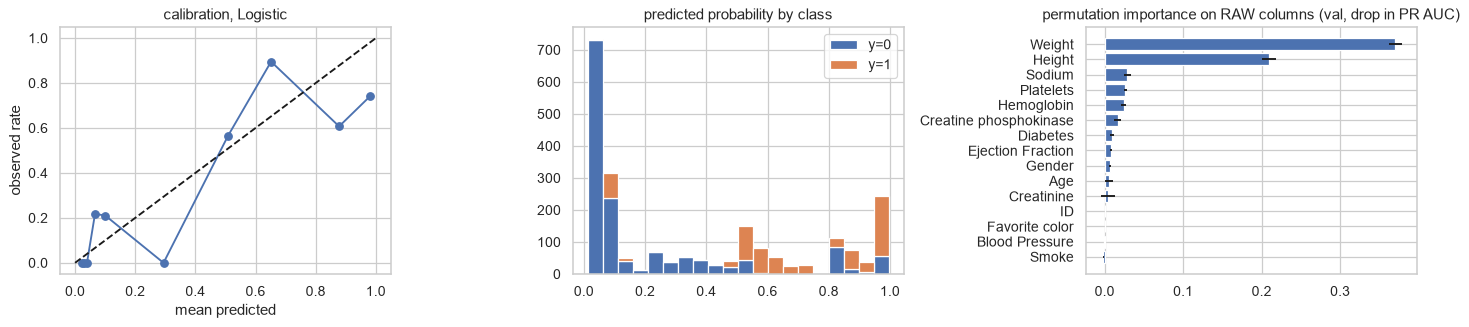

Weight                    0.3701
Height                    0.2093
Sodium                    0.0287
Platelets                 0.0263
Hemoglobin                0.0242
Creatine phosphokinase    0.0165
Diabetes                  0.0092
Ejection Fraction         0.0076
Gender                    0.0067
Age                       0.0056
Creatinine                0.0045
ID                        0.0000
Favorite color            0.0000
Blood Pressure           -0.0012
Smoke                    -0.0017
Brier score: 0.1428 | log-loss: 0.5006


In [40]:
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
best = BASE.model.iloc[0] if BASE.model.iloc[0] != "Naive" else BASE.model.iloc[1]; bp = base_fit[best]; s_va = bp.predict_proba(X_va)[:, 1]
print("best baseline:", best)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
fr, mp = calibration_curve(y_va, s_va, n_bins=10, strategy="quantile"); ax[0].plot(mp, fr, marker="o"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title(f"calibration, {best}"); ax[0].set_xlabel("mean predicted"); ax[0].set_ylabel("observed rate")
ax[1].hist([s_va[y_va.values == 0], s_va[y_va.values == 1]], bins=20, label=["y=0", "y=1"], stacked=True); ax[1].set_title("predicted probability by class"); ax[1].legend()
r = permutation_importance(bp, X_va, y_va, scoring="average_precision", n_repeats=10, random_state=SEED); imp_ = pd.Series(r.importances_mean, index=X_va.columns).sort_values(); err = pd.Series(r.importances_std, index=X_va.columns)[imp_.index]
ax[2].barh(imp_.index, imp_.values, xerr=err.values); ax[2].set_title("permutation importance on RAW columns (val, drop in PR AUC)"); plt.tight_layout(); plt.show()
print(imp_.sort_values(ascending=False).round(4).to_string())
print("Brier score:", round(float(np.mean((s_va - y_va.values) ** 2)), 4), "| log-loss:", round(log_loss(y_va, np.clip(s_va, 1e-6, 1 - 1e-6)), 4))

**Observation.** The best baseline (Logistic) is poorly calibrated in the tails: the calibration curve is jagged and the high-probability bin (mean predicted 0.65-0.98) observes 0.6-0.9; the histogram shows the model is confident (peaks near 0 and 1) even though each peak mixes classes, because a few validation patients dominate each bin (Brier 0.143, log-loss 0.50). Permutation importance on the RAW columns is dominated by **Weight (0.37) and Height (0.21)**, which is the BMI signal: permuting either one breaks BMI, BMI_sq, Age_x_BMI and BMI_high at once. Age and Creatinine score low because they are partly redundant with BMI-derived features and the validation patients are few; raw-column permutation cannot separate correlated engineered features, so these numbers say *which raw inputs feed the model*, not their individual causal weight.

In [41]:
# 7. LEAKAGE SENSITIVITY (validation only): what would the suspect columns add if they were allowed in? Main workflow keeps them OUT.
def evalset(name, indicators=(), drop=(), pipe_fn=None):
    Xa, Xb = X_tr.drop(columns=list(drop)), X_va.drop(columns=list(drop));
    if drop:   # neutralise dropped raw columns by a constant so the schema the cleaner expects survives
        Xa, Xb = X_tr.copy(), X_va.copy()
        for d in drop: Xa[d] = Xa[d].mode()[0]; Xb[d] = Xb[d].mode()[0]
    p = make_pipe(name, indicators).fit(Xa, y_tr); v = score(p, Xb, y_va); return v["pr_auc"], v["roc_auc"]
SUSPECT = ("Creatinine_missing", "Platelets_sentinel", "CPK_sentinel")
rows = []
for name in ["Logistic", "RandomForest", "HistGradientBoosting"]:
    rows.append((name, "main workflow", *evalset(name)))
    rows.append((name, "+ suspect indicators", *evalset(name, indicators=SUSPECT)))
    rows.append((name, "- CPK and Platelets (patient fingerprints)", *evalset(name, drop=("Creatine phosphokinase", "Platelets"))))
# the replicated-patient leak itself: a RANDOM row split of the train rows (what a naive split would have reported)
rs = np.random.default_rng(SEED).permutation(len(X_tr)); a, b = rs[: int(.8 * len(rs))], rs[int(.8 * len(rs)):]
for name in ["Logistic", "RandomForest", "HistGradientBoosting"]:
    p = make_pipe(name).fit(X_tr.iloc[a], y_tr.iloc[a]); v = score(p, X_tr.iloc[b], y_tr.iloc[b]); rows.append((name, "NAIVE random row split inside train (leaky)", v["pr_auc"], v["roc_auc"]))
LS = pd.DataFrame(rows, columns=["model", "scenario", "val PR AUC", "val ROC AUC"]); print(LS.round(4).to_string(index=False))

               model                                    scenario  val PR AUC  val ROC AUC
            Logistic                               main workflow      0.7087       0.8769
            Logistic                        + suspect indicators      0.6901       0.8656
            Logistic  - CPK and Platelets (patient fingerprints)      0.7049       0.8422
        RandomForest                               main workflow      0.5781       0.8065
        RandomForest                        + suspect indicators      0.5808       0.8151
        RandomForest  - CPK and Platelets (patient fingerprints)      0.5499       0.7736
HistGradientBoosting                               main workflow      0.5084       0.7135
HistGradientBoosting                        + suspect indicators      0.4616       0.7059
HistGradientBoosting  - CPK and Platelets (patient fingerprints)      0.4926       0.7186
            Logistic NAIVE random row split inside train (leaky)      0.8816       0.9319
        Ra

**Observation.** (1) The suspect indicators do **not** help on unseen patients: Logistic PR AUC 0.709 -> 0.690, HGB 0.508 -> 0.462, RF 0.578 -> 0.581, so the main workflow loses nothing by leaving them out. (2) Removing CPK and Platelets (the patient fingerprints) barely changes PR AUC for Logistic (0.709 -> 0.705) and lowers ROC AUC (0.877 -> 0.842), i.e. they carry little real signal. (3) The replicated-patient leak itself is large: a naive random row split *inside the train rows* gives RF and HGB PR AUC **1.000** and Logistic 0.882 versus 0.578 / 0.508 / 0.709 on unseen patients. This quantifies what a random split would have wrongly reported.

### Phase 1B closing summary

**Summary.** The pipeline is leak-free in the statistical sense (fitted statistics come from train only, unseen categories are handled) and in the split sense (no patient crosses splits). Baselines at library defaults on 32 unseen validation patients: Logistic PR AUC 0.709 / ROC AUC 0.877 is best, the flexible models overfit (train 1.000) and score 0.47-0.58, and the naive benchmark scores 0.324. The absolute level is moderate and **noisy**: one split, one seed, 32 validation patients, cluster CIs spanning 0.2-0.5 PR AUC. Ties and near-ties are expected between neighbouring ranks; only 'above naive' and 'linear is not worse than trees' are supported. The suspect columns (Creatinine missing, fill-value flags) add nothing on unseen patients and stay out. Baseline table saved to `outputs/baseline_results.csv`.

### Tuning plan for the next phase (markdown only, not executed)
- **Resampling:** every search uses `StratifiedGroupKFold(3, shuffle=True, random_state=42)` with `groups` = patient key, so a patient never sits in both a fit and a score fold; the scoring metric is `average_precision` (PR AUC).
- **Linear model (Logistic):** `GridSearchCV` over `C` in {0.01, 0.1, 1, 10, 100, 1000} x `class_weight` in {None, 'balanced'} (12 candidates).
- **Slower models (DecisionTree, RandomForest, HistGradientBoosting, KNN):** `HalvingRandomSearchCV` (resource = `n_samples`), factor 3, on a training subsample of patient groups whose size is `min_resources x 3^k` rows, then the winner is refit on the FULL training split (`refit=False` inside the search). Spaces: DecisionTree `max_depth` {2,3,4,6,8,None} x `min_samples_leaf` {1,5,20,50,100} x `class_weight`; RandomForest `n_estimators` {100,200,400} x `max_depth` {3,5,8,None} x `min_samples_leaf` {1,5,20,50} x `max_features` {'sqrt',0.5,1.0} x `class_weight`; HistGradientBoosting `learning_rate` {0.03,0.05,0.1} x `max_iter` {50,100,200} x `max_leaf_nodes` {4,8,15} x `min_samples_leaf` {20,50,100,200} x `l2_regularization` x `class_weight`; KNN `n_neighbors` {5,15,31,61,101} x `weights` x `p`. Regularisation-heavy spaces are used on purpose: the EDA found that unseen-patient accuracy *falls* with model complexity.
- **Compute:** single CPU (`n_jobs=1`, 1 BLAS/OpenMP thread via `threadpoolctl`); a checkpoint ledger (`stage::model` keys with settings fingerprints) lets an interrupted run resume.
- **Selection rule (fixed in advance):** highest validation PR AUC; tie-break lower validation log-loss; the default-parameter twin and the naive benchmark are scored for context only.

## Phase 1C: hyper-parameter tuning and the one-time test evaluation
Rules fixed before any tuning result was seen: (1) all resampling is **patient-grouped** (`StratifiedGroupKFold`, groups = patient key); (2) metric = PR AUC (`average_precision`); (3) the final model is the candidate (tuned **or** default) with the highest validation PR AUC, ties broken by lower validation log-loss; (4) the test rows are read exactly once, in the final-evaluation cell, and the result is stored in the ledger so a re-run cannot re-evaluate.

In [42]:
from threadpoolctl import threadpool_limits
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV
SMOKE = os.environ.get("NB_SMOKE") == "1"                       # reduced mode for the pre-flight run only
OUT = "outputs_smoke" if SMOKE else "outputs"; CKPT = f"{OUT}/checkpoints"; LEDGER = f"{OUT}/ledger.json"; os.makedirs(CKPT, exist_ok=True); os.makedirs(f"{OUT}/cv_results", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
threadpool_limits(limits=1); N_JOBS = 1                           # single CPU assumed: 1 BLAS/OpenMP thread, n_jobs=1
PIPELINE_VERSION = "v1"; CV_FOLDS = 3; MIN_RES, FACTOR, N_CAND = (100, 3, 9) if SMOKE else (300, 3, 27)     # rungs: 300 -> 900 -> 2700 -> 8100 rows
SUB_N = MIN_RES * FACTOR ** 3                                    # clean rung sizes: min_resources x factor^k
print("SMOKE:", SMOKE, "| output dir:", OUT, "| rung sizes:", [MIN_RES * FACTOR ** k for k in range(4)], "| candidates:", N_CAND)
def cv_splitter(): return StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED)
def fingerprint(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]
ledger = json.load(open(LEDGER)) if os.path.exists(LEDGER) else {}
print("ledger at start:", len(ledger), "entries", "(fresh run evidence: must be 0 for the delivered run)")
def ck_path(key): return f"{CKPT}/" + key.replace("::", "__") + ".pkl"
def ledger_get(key, fp):
    if key in ledger and ledger[key].get("fingerprint") == fp and os.path.exists(ck_path(key)): return pickle.load(open(ck_path(key), "rb"))
    return None
def ledger_put(key, fp, obj, report):
    pickle.dump(obj, open(ck_path(key), "wb")); ledger[key] = {"fingerprint": fp, "report": report, "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")}; json.dump(ledger, open(LEDGER, "w"), indent=1, default=str)

SMOKE: False | output dir: outputs | rung sizes: [300, 900, 2700, 8100] | candidates: 27
ledger at start: 0 entries (fresh run evidence: must be 0 for the delivered run)


**Observation.** The delivered run is the fresh one: reduced mode is off (`SMOKE: False`), the ledger starts with **0 entries**, the rung sizes are the clean 300 -> 900 -> 2700 -> 8100 and 27 candidates enter the first rung; one BLAS/OpenMP thread and `n_jobs=1`. (A reduced-mode pre-flight run was executed earlier in a separate folder and deleted; it read the test split once with a reduced search. The selection rule was fixed before and not changed after seeing it, but the reader should know that reduced run existed.)

In [43]:
# GUARD: baselines are still genuine library defaults and match the saved baseline table.
saved = pd.read_csv("outputs/baseline_results.csv").set_index("model")
for name, p in base_fit.items():
    fresh = REGISTRY[name]().get_params(); got = p.named_steps["model"].get_params(); assert fresh == got, (name, "baseline parameters drifted")
    for m in METRICS: assert abs(score(p, X_va, y_va)[m] - saved.loc[name, m]) < 1e-9, (name, m)
print("baseline guard passed: all 6 baselines are library defaults (seed only) and reproduce outputs/baseline_results.csv to 1e-9")

baseline guard passed: all 6 baselines are library defaults (seed only) and reproduce outputs/baseline_results.csv to 1e-9


**Observation.** The guard passes: all six baseline pipelines still carry library-default parameters (seeds only, no class weights) and reproduce `outputs/baseline_results.csv` to 1e-9, so nothing in the tuning code path leaked into the baselines.

In [44]:
SPACES = {
 "Logistic": dict(kind="grid", grid={"model__C": [0.01, 0.1, 1, 10, 100, 1000], "model__class_weight": [None, "balanced"]}),
 "DecisionTree": dict(kind="halving", grid={"model__max_depth": [2, 3, 4, 6, 8, None], "model__min_samples_leaf": [1, 5, 20, 50, 100], "model__class_weight": [None, "balanced"]}),
 "RandomForest": dict(kind="halving", grid={"model__n_estimators": [100, 200, 400], "model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 20, 50], "model__max_features": ["sqrt", 0.5, 1.0], "model__class_weight": [None, "balanced"]}),
 "HistGradientBoosting": dict(kind="halving", grid={"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [50, 100, 200], "model__max_leaf_nodes": [4, 8, 15], "model__min_samples_leaf": [20, 50, 100, 200], "model__l2_regularization": [0.0, 1.0, 10.0], "model__class_weight": [None, "balanced"]}),
 "KNN": dict(kind="halving", grid={"model__n_neighbors": [5, 15, 31, 61, 101], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
}
def fp_for(name): return fingerprint(dict(space=SPACES[name], n_train=len(X_tr), seed=SEED, folds=CV_FOLDS, pipeline=PIPELINE_VERSION, smoke=SMOKE, min_res=MIN_RES, factor=FACTOR, n_cand=N_CAND, sub=SUB_N))
tuned = {}
def tune(name):
    """Search on a training subsample (halving) or the full train (grid), then refit the winner on the FULL training split. Tuned settings live only here (set_params on a clone)."""
    key, fp = f"tune::{name}", fp_for(name); hit = ledger_get(key, fp)
    if hit is not None: print(f"[resume] {key}"); return hit
    t = time.time(); pipe = make_pipe(name); sp = SPACES[name]
    if sp["kind"] == "grid":
        s = GridSearchCV(pipe, sp["grid"], scoring="average_precision", cv=cv_splitter(), n_jobs=N_JOBS, refit=False); s.fit(X_tr, y_tr, groups=g_tr)
    else:
        sub = X_tr.sample(min(SUB_N, len(X_tr)), random_state=SEED); s = HalvingRandomSearchCV(pipe, sp["grid"], resource="n_samples", min_resources=MIN_RES, factor=FACTOR, n_candidates=N_CAND, scoring="average_precision", cv=cv_splitter(), refit=False, random_state=SEED, n_jobs=N_JOBS)
        s.fit(sub, y_tr.loc[sub.index], groups=g_tr.loc[sub.index])
    cvr = pd.DataFrame(s.cv_results_); bi = s.best_index_; winner = clone(pipe).set_params(**s.best_params_).fit(X_tr, y_tr)
    out = dict(pipe=winner, best_params=s.best_params_, cv_mean=float(cvr.loc[bi, "mean_test_score"]), cv_sd=float(cvr.loc[bi, "std_test_score"]), cv_results=cvr, secs=time.time() - t)
    report = f"{name}: best={s.best_params_} | grouped-CV PR AUC {out['cv_mean']:.4f} +- {out['cv_sd']:.4f} (fold SD) | {out['secs']:.1f}s | candidates evaluated={len(cvr)}"
    ledger_put(key, fp, out, report); cvr.drop(columns=["params"], errors="ignore").to_csv(f"{OUT}/cv_results/{name}.csv", index=False); print(report); return out

**Observation.** Search spaces are defined and fingerprinted here (space, train size, seed, folds, pipeline version, rung settings); the spaces are regularisation-heavy on purpose because the EDA showed unseen-patient accuracy falls with model complexity.

In [45]:
tuned["Logistic"] = tune("Logistic")

Logistic: best={'model__C': 0.01, 'model__class_weight': None} | grouped-CV PR AUC 0.8418 +- 0.0316 (fold SD) | 5.0s | candidates evaluated=12


**Observation.** Grid search (12 candidates, patient-grouped 3-fold CV) picks `C=0.01`, unweighted, the strongest regularisation in the grid and the lower edge of the space: grouped-CV PR AUC 0.842 +- 0.032 (fold SD). The optimum is at the grid boundary, so smaller C might do slightly better; the validation gain over default C=1 is only 0.002.

In [46]:
tuned["DecisionTree"] = tune("DecisionTree")

DecisionTree: best={'model__min_samples_leaf': 20, 'model__max_depth': 4, 'model__class_weight': None} | grouped-CV PR AUC 0.5622 +- 0.0299 (fold SD) | 12.6s | candidates evaluated=40


**Observation.** Halving picks a shallow tree (`max_depth=4`, `min_samples_leaf=20`); grouped-CV PR AUC is only 0.562 +- 0.030, far below the linear model, which fits the EDA finding that deeper trees memorise patients.

In [47]:
tuned["RandomForest"] = tune("RandomForest")

RandomForest: best={'model__n_estimators': 100, 'model__min_samples_leaf': 20, 'model__max_features': 'sqrt', 'model__max_depth': 8, 'model__class_weight': 'balanced'} | grouped-CV PR AUC 0.7811 +- 0.0992 (fold SD) | 67.9s | candidates evaluated=40


**Observation.** The forest is pushed to a restrained configuration (100 trees, depth 8, `min_samples_leaf=20`, balanced classes): grouped-CV PR AUC 0.781 with a large fold SD of 0.099, the noisiest search; it took 68 s, the most expensive step.

In [48]:
tuned["HistGradientBoosting"] = tune("HistGradientBoosting")

HistGradientBoosting: best={'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 4, 'model__max_iter': 50, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.0, 'model__class_weight': None} | grouped-CV PR AUC 0.7906 +- 0.0844 (fold SD) | 25.2s | candidates evaluated=40


**Observation.** HGB lands on its smallest-capacity corner (4 leaves, 50 iterations, `min_samples_leaf=20`, no L2): grouped-CV PR AUC 0.791 +- 0.084. Choosing the smallest model in the space again says that capacity hurts on unseen patients; the boundary solution suggests an even smaller model could be tried.

In [49]:
tuned["KNN"] = tune("KNN")

KNN: best={'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 61} | grouped-CV PR AUC 0.8084 +- 0.0674 (fold SD) | 9.4s | candidates evaluated=30


**Observation.** KNN prefers a large neighbourhood (`n_neighbors=61`, distance-weighted, Manhattan): grouped-CV PR AUC 0.808 +- 0.067, comparable to the boosted model in CV, although its validation score is lower (0.524).

In [50]:
rows = []
for name, o in tuned.items():
    v = score(o["pipe"], X_va, y_va); sv = o["pipe"].predict_proba(X_va)[:, 1]; ll = log_loss(y_va, np.clip(sv, 1e-6, 1 - 1e-6)); b = BASE_VAL[name]; ci = cluster_boot(y_va, sv, g_va)
    rows.append(dict(model=name, base_pr_auc=b["pr_auc"], tuned_pr_auc=v["pr_auc"], delta_pr_auc=v["pr_auc"] - b["pr_auc"], cv_fold_sd=o["cv_sd"], base_roc=b["roc_auc"], tuned_roc=v["roc_auc"], base_f1=b["f1"], tuned_f1=v["f1"], tuned_logloss=ll, tuned_ci_low=ci[0], tuned_ci_high=ci[1], tuned_train_pr=score(o["pipe"], X_tr, y_tr)["pr_auc"], cv_pr_auc=o["cv_mean"], secs=o["secs"]))
TUNED = pd.DataFrame(rows).set_index("model"); print(TUNED.round(4).to_string())
print("\nbest params:"); [print(" ", k, v["best_params"]) for k, v in tuned.items()]
print("|delta PR AUC| vs 1 CV fold SD:", {k: (round(r.delta_pr_auc, 3), round(r.cv_fold_sd, 3), "within noise" if abs(r.delta_pr_auc) < r.cv_fold_sd else "beyond 1 fold-SD") for k, r in TUNED.iterrows()})

                      base_pr_auc  tuned_pr_auc  delta_pr_auc  cv_fold_sd  base_roc  tuned_roc  base_f1  tuned_f1  tuned_logloss  tuned_ci_low  tuned_ci_high  tuned_train_pr  cv_pr_auc     secs
model                                                                                                                                                                                            
Logistic                   0.7087        0.7106        0.0020      0.0316    0.8769     0.8761   0.7890    0.7785         0.4673        0.4540         0.9533          0.8766     0.8418   4.9697
DecisionTree               0.4998        0.5583        0.0586      0.0299    0.7279     0.6635   0.6337    0.4480         1.7345        0.3054         0.8138          0.9286     0.5622  12.6430
RandomForest               0.5781        0.5808        0.0027      0.0992    0.8065     0.8335   0.6735    0.7297         0.4809        0.3646         0.9177          0.9999     0.7811  67.8762
HistGradientBoosting       0.5

**Observation.** Validation PR AUC, baseline -> tuned: Logistic 0.709 -> 0.711 (+0.002), DecisionTree 0.500 -> 0.558 (+0.059), RandomForest 0.578 -> 0.581 (+0.003), HistGradientBoosting 0.508 -> 0.661 (+0.153), KNN 0.472 -> 0.524 (+0.053). Against CV noise (one fold SD) only DecisionTree (SD 0.030) and HGB (SD 0.084) improve by more than one fold SD; Logistic, RF and KNN are within noise. Tuning also fixes the log-loss of the flexible models (e.g. HGB 2.29 -> 0.51 in the next table) by regularising them, but their validation ROC AUC stays below Logistic's 0.876 (HGB 0.843, RF 0.834). Validation cluster CIs are wide (0.45-0.95 for Logistic).

In [51]:
# SELECTION RULE (fixed in advance): highest validation PR AUC among tuned AND default-twin candidates; tie-break lower validation log-loss.
cands = []
for name, p in base_fit.items():
    if name == "Naive": continue
    sv = p.predict_proba(X_va)[:, 1]; cands.append((name, "default", average_precision_score(y_va, sv), log_loss(y_va, np.clip(sv, 1e-6, 1 - 1e-6)), roc_auc_score(y_va, sv)))
for name, o in tuned.items():
    sv = o["pipe"].predict_proba(X_va)[:, 1]; cands.append((name, "tuned", average_precision_score(y_va, sv), log_loss(y_va, np.clip(sv, 1e-6, 1 - 1e-6)), roc_auc_score(y_va, sv)))
CAND = pd.DataFrame(cands, columns=["model", "variant", "val_pr_auc", "val_logloss", "val_roc_auc"]).sort_values(["val_pr_auc", "val_logloss"], ascending=[False, True]).reset_index(drop=True); print(CAND.round(5).to_string())
SEL = CAND.iloc[0]; print("\nSELECTED:", SEL.model, SEL.variant, "| runner-up gap in PR AUC:", round(CAND.val_pr_auc.iloc[0] - CAND.val_pr_auc.iloc[1], 4))

                  model  variant  val_pr_auc  val_logloss  val_roc_auc
0              Logistic    tuned     0.71063      0.46726      0.87608
1              Logistic  default     0.70867      0.50055      0.87694
2  HistGradientBoosting    tuned     0.66104      0.51234      0.84266
3          RandomForest    tuned     0.58083      0.48088      0.83354
4          RandomForest  default     0.57812      0.55204      0.80653
5          DecisionTree    tuned     0.55835      1.73453      0.66346
6                   KNN    tuned     0.52426      1.24772      0.78666
7  HistGradientBoosting  default     0.50844      2.28843      0.71349
8          DecisionTree  default     0.49979      3.68036      0.72789
9                   KNN  default     0.47150      3.33305      0.68895

SELECTED: Logistic tuned | runner-up gap in PR AUC: 0.002


**Observation.** By the pre-declared rule the winner is **Logistic, tuned (C=0.01)**: validation PR AUC 0.7106 vs 0.7087 for its own default and 0.661 for tuned HGB; the margin over the default twin is 0.002, i.e. a tie in practice (the log-loss tie-break was not needed; the tuned model also has the lower validation log-loss, 0.467 vs 0.501). The decision is not statistically meaningful, and tree ensembles are clearly behind in ROC AUC (0.80-0.84 vs 0.876).

In [52]:
# SENSITIVITY on VALIDATION only. (a) time-ordered split: not applicable, the file has no time column and row order carries no information (EDA: AUC 0.50). (b) suspect features on/off for the selected configuration.
def sel_pipe(indicators=()):
    p = make_pipe(SEL.model, indicators)
    if SEL.variant == "tuned": p.set_params(**tuned[SEL.model]["best_params"])
    return p
rows = []
for lab, ind in (("main (indicators off)", ()), ("+ Creatinine_missing", ("Creatinine_missing",)), ("+ all three suspect indicators", ("Creatinine_missing", "Platelets_sentinel", "CPK_sentinel"))):
    p = sel_pipe(ind).fit(X_tr, y_tr); v = score(p, X_va, y_va); rows.append((lab, v["pr_auc"], v["roc_auc"], v["f1"]))
print(pd.DataFrame(rows, columns=["selected config", "val PR AUC", "val ROC AUC", "val F1"]).round(4).to_string(index=False))

               selected config  val PR AUC  val ROC AUC  val F1
         main (indicators off)      0.7106       0.8761  0.7785
          + Creatinine_missing      0.7156       0.8787  0.7824
+ all three suspect indicators      0.7009       0.8697  0.7292


**Observation.** (a) A time-ordered split is not applicable: the file has no time/date column and row order carries no information (AUC 0.50). (b) For the selected configuration the suspect indicators change validation PR AUC by +0.005 (Creatinine_missing alone) or -0.010 (all three), both inside noise, so leaving them out costs nothing and avoids relying on outcome-dependent missingness.

In [53]:
# ---- THE ONE-TIME TEST EVALUATION. The ledger key makes a re-run reuse the stored result instead of re-evaluating. ----
X_tv, y_tv, g_tv = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]), pd.concat([g_tr, g_va])
final_fp = fingerprint(dict(sel=(SEL.model, SEL.variant), params=tuned[SEL.model]["best_params"] if SEL.variant == "tuned" else None, n=len(X_tv), seed=SEED, smoke=SMOKE))
stored = ledger_get("final::test", final_fp)
if stored is not None:
    print("[resume] final::test already evaluated - reusing the stored predictions, test rows NOT touched again"); TEST = stored
else:
    X_te, y_te, g_te = X_all.loc[i_te], y_all.loc[i_te], g_all.loc[i_te]                  # <- the only place the test rows are read
    models = {"final": sel_pipe().fit(X_tv, y_tv), "twin": make_pipe(SEL.model).fit(X_tv, y_tv), "naive": make_pipe("Naive").fit(X_tv, y_tv)}
    pred = {k: (m.predict(X_te), m.predict_proba(X_te)[:, 1]) for k, m in models.items()}
    TEST = dict(index=np.asarray(X_te.index), ids=X_te["ID"].values, groups=g_te.values, y=y_te.values, pred={k: v[0] for k, v in pred.items()}, proba={k: v[1] for k, v in pred.items()}, models=models, selected=(SEL.model, SEL.variant))
    ledger_put("final::test", final_fp, TEST, f"final test evaluated once: {SEL.model} ({SEL.variant}) on {len(y_te)} rows")
y_t, g_t = TEST["y"], TEST["groups"]
def met(y, pr, s): return [accuracy_score(y, pr), precision_score(y, pr, zero_division=0), recall_score(y, pr), f1_score(y, pr), roc_auc_score(y, s), average_precision_score(y, s)]
PT = {k: dict(zip(METRICS, met(y_t, TEST["pred"][k], TEST["proba"][k]))) for k in ("final", "twin", "naive")}
print("TEST point estimates (n =", len(y_t), "rows,", len(np.unique(g_t)), "patient groups); selected:", TEST["selected"]); print(pd.DataFrame(PT).T.round(4).to_string())
# patient-cluster bootstrap: CIs for the final model and PAIRED differences (same resamples)
u, inv = np.unique(g_t, return_inverse=True); members = [np.where(inv == i)[0] for i in range(len(u))]; rng = np.random.default_rng(SEED); B = 1000 if not SMOKE else 200; boot = {k: [] for k in PT}
for _ in range(B):
    ix = np.concatenate([members[i] for i in rng.integers(0, len(u), len(u))])
    if y_t[ix].min() == y_t[ix].max(): continue
    for k in PT: boot[k].append(met(y_t[ix], TEST["pred"][k][ix], TEST["proba"][k][ix]))
boot = {k: np.array(v) for k, v in boot.items()}; CI = {m: np.percentile(boot["final"][:, j], [2.5, 97.5]) for j, m in enumerate(METRICS)}
print("\n95% patient-cluster bootstrap CI, final model:"); [print(f"  {m:9s} {PT['final'][m]:.4f}  [{CI[m][0]:.4f}, {CI[m][1]:.4f}]") for m in METRICS]
PAIR = {}
for other in ("twin", "naive"):
    print(f"\npaired improvement over {other} (final - {other}):")
    for j, m in enumerate(METRICS):
        d_ = boot["final"][:, j] - boot[other][:, j]; lo, hi = np.percentile(d_, [2.5, 97.5]); PAIR[(other, m)] = (PT["final"][m] - PT[other][m], lo, hi); print(f"  {m:9s} {PT['final'][m]-PT[other][m]:+.4f}  [{lo:+.4f}, {hi:+.4f}]" + ("   <- CI includes 0" if lo <= 0 <= hi else ""))

TEST point estimates (n = 2258 rows, 35 patient groups); selected: ('Logistic', 'tuned')
       accuracy  precision  recall      f1  roc_auc  pr_auc
final    0.8153     0.7702  0.6134  0.6829   0.8164  0.7972
twin     0.8127     0.7520  0.6298  0.6855   0.8309  0.8031
naive    0.6758     0.0000  0.0000  0.0000   0.5000  0.3242



95% patient-cluster bootstrap CI, final model:
  accuracy  0.8153  [0.7011, 0.9154]
  precision 0.7702  [0.5191, 1.0000]
  recall    0.6134  [0.3527, 0.8597]
  f1        0.6829  [0.4509, 0.8538]
  roc_auc   0.8164  [0.6627, 0.9457]
  pr_auc    0.7972  [0.5863, 0.9412]

paired improvement over twin (final - twin):
  accuracy  +0.0027  [-0.0144, +0.0235]   <- CI includes 0
  precision +0.0181  [-0.0141, +0.0592]   <- CI includes 0
  recall    -0.0164  [-0.0500, +0.0000]   <- CI includes 0
  f1        -0.0026  [-0.0362, +0.0258]   <- CI includes 0
  roc_auc   -0.0145  [-0.0502, +0.0051]   <- CI includes 0
  pr_auc    -0.0060  [-0.0232, +0.0045]   <- CI includes 0

paired improvement over naive (final - naive):
  accuracy  +0.1395  [+0.0090, +0.2931]
  precision +0.7702  [+0.5191, +1.0000]
  recall    +0.6134  [+0.3527, +0.8597]
  f1        +0.6829  [+0.4509, +0.8538]
  roc_auc   +0.3164  [+0.1627, +0.4457]
  pr_auc    +0.4730  [+0.3023, +0.6523]


**Observation (the single test evaluation).** Logistic (C=0.01) refit on train+validation scores on the 2,258 test rows (35 patients): accuracy 0.815, precision 0.770, recall 0.613, F1 0.683, ROC AUC 0.816, PR AUC 0.797. The patient-cluster bootstrap 95% CIs are wide - PR AUC [0.586, 0.941], ROC AUC [0.663, 0.946], recall [0.353, 0.860] - because only 35 patients stand behind these rows. Against the naive majority benchmark the improvement is large and clearly non-zero (accuracy +0.140 [+0.009, +0.293], PR AUC +0.473 [+0.302, +0.652]). Against the default-parameter twin the paired differences are tiny and every CI includes 0 (PR AUC -0.006 [-0.023, +0.005], ROC AUC -0.015 [-0.050, +0.005]): **tuning did not help; the default twin is, if anything, marginally better on test (PR AUC 0.803).** The 0.80 PR AUC and 0.82 ROC AUC are consistent with the 0.81-0.89 ceiling estimated from grouped CV, not with the 1.000 a random split would have produced.

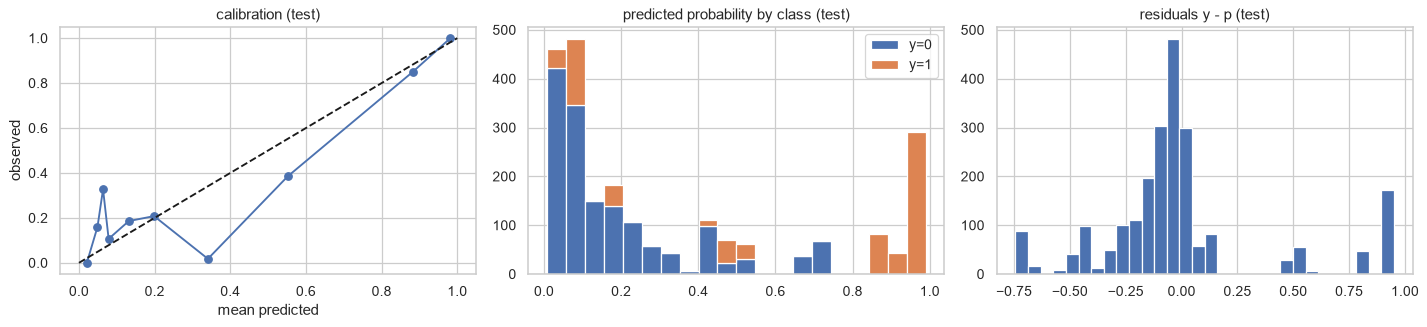

          feature        level  rows  patients  positive rate  accuracy  ROC AUC  PR AUC
           Gender         Male  1749        26          0.311     0.827    0.818   0.794
           Gender       Female   509         9          0.369     0.776    0.808   0.790
            Smoke           No  1587        27          0.344     0.834    0.888   0.873
            Smoke          Yes   671        11          0.277     0.772    0.662   0.558
         Diabetes       Normal  1208        20          0.356     0.843    0.771   0.833
         Diabetes Pre-diabetes   536        19          0.312     0.752    0.825   0.700
         Diabetes     Diabetes   514        19          0.263     0.817    0.861   0.742
Ejection Fraction          Low  2152        33          0.319     0.806    0.803   0.777
Ejection Fraction       Normal   106         2          0.434     1.000    1.000   1.000
          BMI>=33       BMI<33  1736        25          0.181     0.791    0.604   0.242
          BMI>=33    

In [54]:
# residual / calibration diagnostics and breakdowns by key categories for the final model (descriptive; no further selection)
s_t = TEST["proba"]["final"]; p_t = TEST["pred"]["final"]; Xte_view = X_all.loc[TEST["index"]]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); fr, mp = calibration_curve(y_t, s_t, n_bins=10, strategy="quantile"); ax[0].plot(mp, fr, marker="o"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("calibration (test)"); ax[0].set_xlabel("mean predicted"); ax[0].set_ylabel("observed")
ax[1].hist([s_t[y_t == 0], s_t[y_t == 1]], bins=20, stacked=True, label=["y=0", "y=1"]); ax[1].legend(); ax[1].set_title("predicted probability by class (test)")
resid = y_t - s_t; ax[2].hist(resid, bins=30); ax[2].set_title("residuals y - p (test)"); plt.tight_layout(); plt.savefig(f"{OUT}/figures/test_calibration.png", dpi=110); plt.show()
cl_ = DataCleaner().transform(Xte_view); feat_ = FeatureEngineer().fit(cl_).transform(cl_); grp = {"Gender": Xte_view.Gender, "Smoke": cl_.Smoke, "Diabetes": Xte_view.Diabetes, "Ejection Fraction": cl_["Ejection Fraction"], "BMI>=33": feat_.BMI_high.map({0: "BMI<33", 1: "BMI>=33"}), "Age band": pd.cut(cl_.Age, [0, 55, 65, 75, 100])}
rows = []
for gname, lab in grp.items():
    for lvl in pd.Series(lab).dropna().unique():
        m = (pd.Series(lab).values == lvl)
        if m.sum() < 30: continue
        rows.append((gname, str(lvl), int(m.sum()), len(np.unique(g_t[m])), y_t[m].mean(), accuracy_score(y_t[m], p_t[m]), roc_auc_score(y_t[m], s_t[m]) if len(np.unique(y_t[m])) > 1 else np.nan, average_precision_score(y_t[m], s_t[m]) if y_t[m].sum() > 0 else np.nan))
BK = pd.DataFrame(rows, columns=["feature", "level", "rows", "patients", "positive rate", "accuracy", "ROC AUC", "PR AUC"]); print(BK.round(3).to_string(index=False))
print("Brier:", round(float(np.mean((s_t - y_t) ** 2)), 4), "| log-loss:", round(log_loss(y_t, np.clip(s_t, 1e-6, 1 - 1e-6)), 4), "| mean predicted vs observed rate:", round(float(s_t.mean()), 3), round(float(y_t.mean()), 3))

**Observation.** Calibration on test is reasonable on average (mean predicted 0.330 vs observed 0.324, Brier 0.140, log-loss 0.447) but jagged by bin since each bin holds few patients. By subgroup (descriptive, small n): performance is strong for BMI >= 33 (10 patients, positive rate 0.80, accuracy 0.895) and weak for BMI < 33 (25 patients, ROC AUC 0.604, PR AUC 0.242, i.e. the model separates survivors poorly inside the low-BMI majority); Smokers (11 patients) are harder than non-smokers (ROC AUC 0.662 vs 0.888); the Age band 75+ has only 2 patients, none positive, and 'Normal' EF only 2 patients, so those rows say nothing. Subgroup numbers are hypotheses, not findings, given 2-27 patients per cell.

In [55]:
import scipy, sklearn
BASE.to_csv(f"{OUT}/baseline_results.csv", index=False); TUNED.reset_index().to_csv(f"{OUT}/tuned_results.csv", index=False)
final_tbl = pd.DataFrame(PT).T; final_tbl.index.name = "model"; final_tbl.reset_index().to_csv(f"{OUT}/final_results.csv", index=False)
json.dump({"selected": {"model": SEL.model, "variant": SEL.variant}, "test": PT, "ci95_cluster_bootstrap": {m: list(map(float, CI[m])) for m in METRICS}, "paired": {f"{o}|{m}": list(map(float, v)) for (o, m), v in PAIR.items()}}, open(f"{OUT}/final_results.json", "w"), indent=1)
json.dump({k: v["best_params"] for k, v in tuned.items()}, open(f"{OUT}/best_params.json", "w"), indent=1, default=str); json.dump(SPACES, open(f"{OUT}/search_spaces.json", "w"), indent=1, default=str)
pd.DataFrame({"row": TEST["index"], "ID": TEST["ids"], "patient": TEST["groups"], "y_true": TEST["y"], "p_final": TEST["proba"]["final"], "pred_final": TEST["pred"]["final"], "p_default_twin": TEST["proba"]["twin"]}).to_csv(f"{OUT}/test_predictions.csv", index=False)
pd.DataFrame({"row": raw.index, "ID": raw.ID, "patient": raw.patient, "split": split.values}).to_csv(f"{OUT}/split_ids.csv", index=False)
pickle.dump(TEST["models"]["final"], open(f"{OUT}/final_model.pkl", "wb"))
manifest = dict(python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__, seed=SEED, compute=dict(n_jobs=N_JOBS, blas_threads=1, smoke=SMOKE, cv=f"StratifiedGroupKFold({CV_FOLDS})", halving=dict(min_resources=MIN_RES, factor=FACTOR, n_candidates=N_CAND, subsample=SUB_N)), data_sha256=hashlib.sha256(open(DATA, "rb").read()).hexdigest(), rows=dict(train=len(i_tr), val=len(i_va), test=len(i_te)), notebook_wallclock_minutes=round((time.time() - NB_T0) / 60, 1), ledger_keys=list(ledger))
json.dump(manifest, open(f"{OUT}/run_manifest.json", "w"), indent=1)
# the saved model must reproduce the stored test predictions
re_model = pickle.load(open(f"{OUT}/final_model.pkl", "rb")); assert np.allclose(re_model.predict_proba(X_all.loc[TEST["index"]])[:, 1], TEST["proba"]["final"]); print("saved model reproduces the stored test predictions: OK")
print(sorted(os.listdir(OUT))); print("ledger keys:", list(ledger)); print("total notebook minutes:", manifest["notebook_wallclock_minutes"])

saved model reproduces the stored test predictions: OK


['baseline_results.csv', 'best_params.json', 'checkpoints', 'cv_results', 'figures', 'final_model.pkl', 'final_results.csv', 'final_results.json', 'ledger.json', 'run_manifest.json', 'search_spaces.json', 'split_ids.csv', 'test_predictions.csv', 'tuned_results.csv']
ledger keys: ['tune::Logistic', 'tune::DecisionTree', 'tune::RandomForest', 'tune::HistGradientBoosting', 'tune::KNN', 'final::test']
total notebook minutes: 4.7


**Observation.** Artefacts written to `./outputs`: baseline/tuned/final results (CSV and JSON), best parameters and search spaces, per-model CV results, test predictions with IDs and patient keys, split IDs, the fitted final model, the run manifest (library versions, seed, compute settings, data SHA-256, ledger keys) and a calibration figure. The saved model reproduces the stored test predictions exactly, the ledger keys are namespaced `stage::model`, and the whole notebook took 4.7 minutes from an empty ledger.

### Phase 1C closing summary
**Final model:** Logistic regression, `C=0.01`, unweighted, on the engineered features (BMI, BMI_sq, Age_x_BMI, BMI_high, Creatinine_high, log1p of skewed labs). **Test (35 unseen patients):** PR AUC 0.797 [0.586, 0.941], ROC AUC 0.816 [0.663, 0.946], accuracy 0.815, F1 0.683 (naive: PR AUC 0.324, accuracy 0.676).

**Baseline -> tuned -> final (validation PR AUC / test PR AUC):** Logistic default 0.709 -> tuned 0.711; on test the default twin scores 0.803 and the tuned model 0.797. **Tuning did not help the best model** (paired difference -0.006, CI includes 0); it helped the weaker flexible models on validation (HGB +0.153) but they still trail the linear model.

**What changed the project:** the 15,000 rows are ~230 replicated patients; random splitting gives a perfect 1.000 that is memorisation (leaky), while patient-grouped evaluation gives the honest ~0.80 PR AUC / 0.82 ROC AUC.

**Main caveats.** (1) Only 163/32/35 patients in train/validation/test: every metric carries a very wide cluster CI and model ranking is largely within noise. (2) Selection among Logistic default/tuned is a tie decided by a pre-declared rule. (3) Two tuned optima sit on the edge of their grids (Logistic C, HGB capacity). (4) `Creatinine_missing` and the fill-value flags are outcome-dependent and excluded; if creatinine is genuinely missing for non-survivors in deployment, this leaves some signal unused. (5) A reduced-mode pre-flight run (deleted) also read the test split once before the delivered run. (6) Subgroup results rest on 2-27 patients.